In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_excel("ott_viewer_dropoff_retention_us_v1.0.xlsx")
df.head()

,show_id,title,platform,genre,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,...,pause_count,rewind_count,skip_intro,cognitive_load,attention_required,night_watch_safe,drop_off,drop_off_probability,retention_risk,dataset_version
0,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016,1,1,48,4,5,...,3,0,0,9,high,0,1,0.649,high,v1.0
1,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016,1,2,55,5,4,...,3,3,1,5,medium,0,0,0.473,medium,v1.0
2,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016,1,3,51,4,8,...,4,2,0,9,high,0,0,0.583,medium,v1.0
3,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016,1,4,50,4,7,...,4,1,0,7,high,0,0,0.520,medium,v1.0
4,66732,Stranger Things,Netflix,Sci-Fi & Fantasy,2016,1,5,52,4,3,...,3,0,1,7,high,0,1,0.638,high,v1.0


In [2]:
# Checking Dimensions
df.shape
# checking columns
df.columns
# checking datatypes
df.dtypes
# check missing values
df.isna()
# check duplicate records
df.duplicated().any()

False

In [3]:
df.columns

Index(['show_id', 'title', 'platform', 'genre', 'release_year',
       'season_number', 'episode_number', 'episode_duration_min',
       'pacing_score', 'hook_strength', 'dialogue_density', 'visual_intensity',
       'avg_watch_percentage', 'pause_count', 'rewind_count', 'skip_intro',
       'cognitive_load', 'attention_required', 'night_watch_safe', 'drop_off',
       'drop_off_probability', 'retention_risk', 'dataset_version'],
      dtype='str')

UNIVARIATE ANALYSIS

CATEGORICAL COLUMNS

In [4]:
# Finding the categorical Columns
import pandas as pd
df=pd.read_excel("ott_viewer_dropoff_retention_us_v1.0.xlsx")
categorical_cols = df.select_dtypes(include='str').columns

numerical_cols = df.select_dtypes(include='number').columns

print("Categorical Columns:")
print(categorical_cols)

print("\nNumerical Columns:")
print(numerical_cols)

print("\nCategorical Unique Values:")
print(df[categorical_cols].nunique())
# checking them 
df[categorical_cols].head()
categorical_eda_cols = [
    'platform',
    'genre',
    'dialogue_density',
    'attention_required',
    'retention_risk',
    'night_watch_safe',
    'drop_off'
]
numerical_eda_cols = [
    'release_year',
    'season_number',
    'episode_number',
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'avg_watch_percentage',
    'pause_count',
    'rewind_count',
    'skip_intro',
    'cognitive_load',
    'drop_off_probability'
]
df['attention_required'].value_counts()



Categorical Columns:
Index(['platform', 'genre', 'dialogue_density', 'attention_required',
       'retention_risk', 'dataset_version'],
      dtype='str')

Numerical Columns:
Index(['show_id', 'release_year', 'season_number', 'episode_number',
       'episode_duration_min', 'pacing_score', 'hook_strength',
       'visual_intensity', 'avg_watch_percentage', 'pause_count',
       'rewind_count', 'skip_intro', 'cognitive_load', 'night_watch_safe',
       'drop_off', 'drop_off_probability'],
      dtype='str')

Categorical Unique Values:
platform              28
genre                 16
dialogue_density       3
attention_required     2
retention_risk         3
dataset_version        1
dtype: int64


attention_required
high      16878
medium    16293
Name: count, dtype: int64

In [5]:
for col in categorical_eda_cols:
    print(f"\n{'='*40}")
    print(f"{col.upper()}")
    print(f"{'='*40}")
    print(df[col].value_counts())


PLATFORM
platform
Netflix                             12270
Hulu                                 7967
Prime Video                          2693
Disney+                              2467
Kocowa Amazon Channel                2245
OnDemandKorea                        1582
Rakuten Viki                          911
Peacock Premium                       686
fuboTV                                550
Crunchyroll                           446
HBO Max                               319
Paramount Plus Apple TV Channel       311
Britbox Apple TV Channel              167
YouTube Premium                       129
Apple TV                               70
Philo                                  55
YouTube TV                             54
Spectrum On Demand                     48
Shahid VIP                             40
Paramount+ Amazon Channel              30
Kocowa                                 27
PBS Documentaries Amazon Channel       27
AMC Plus Apple TV Channel              25
HiDive         

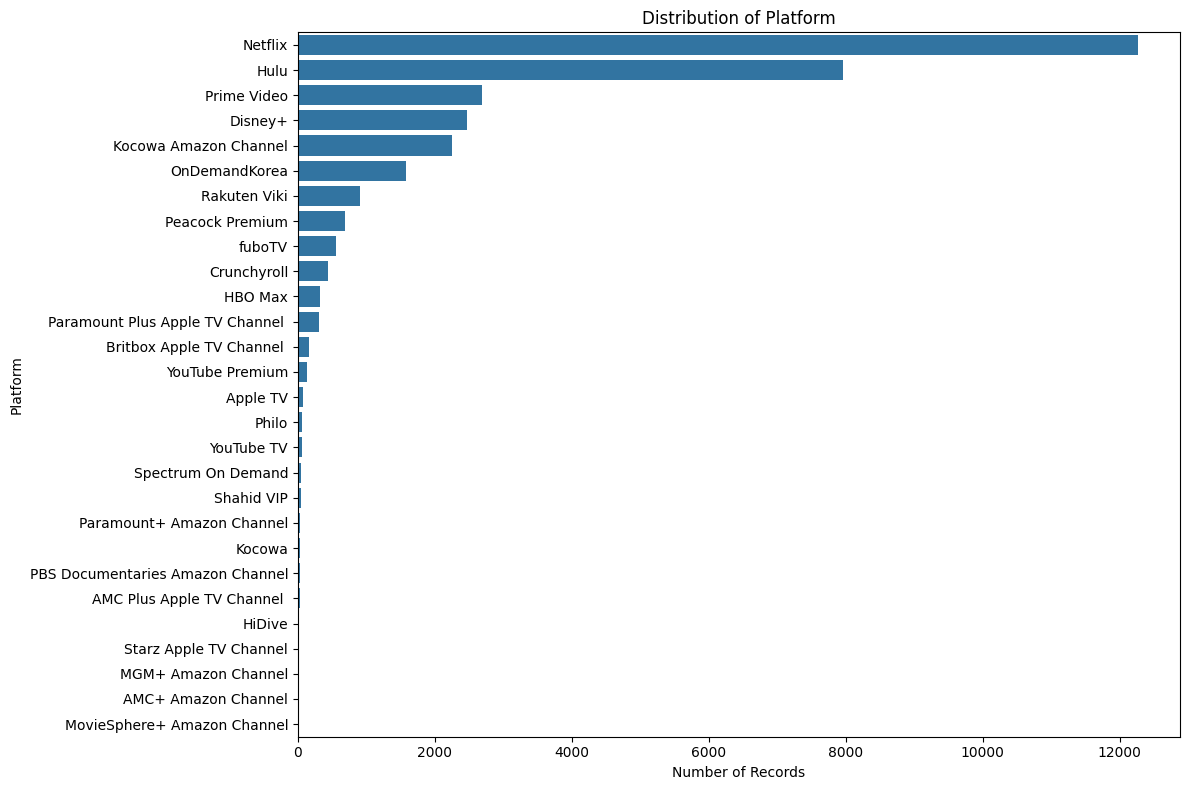

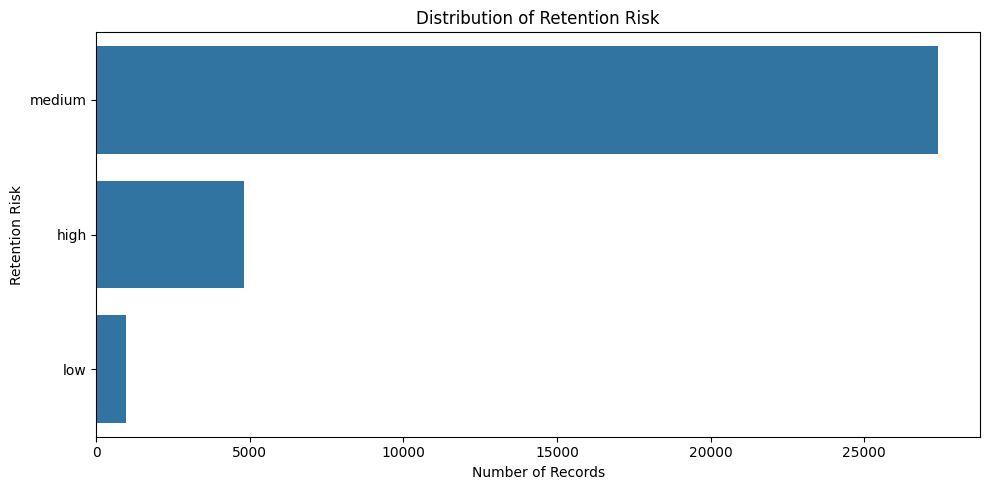

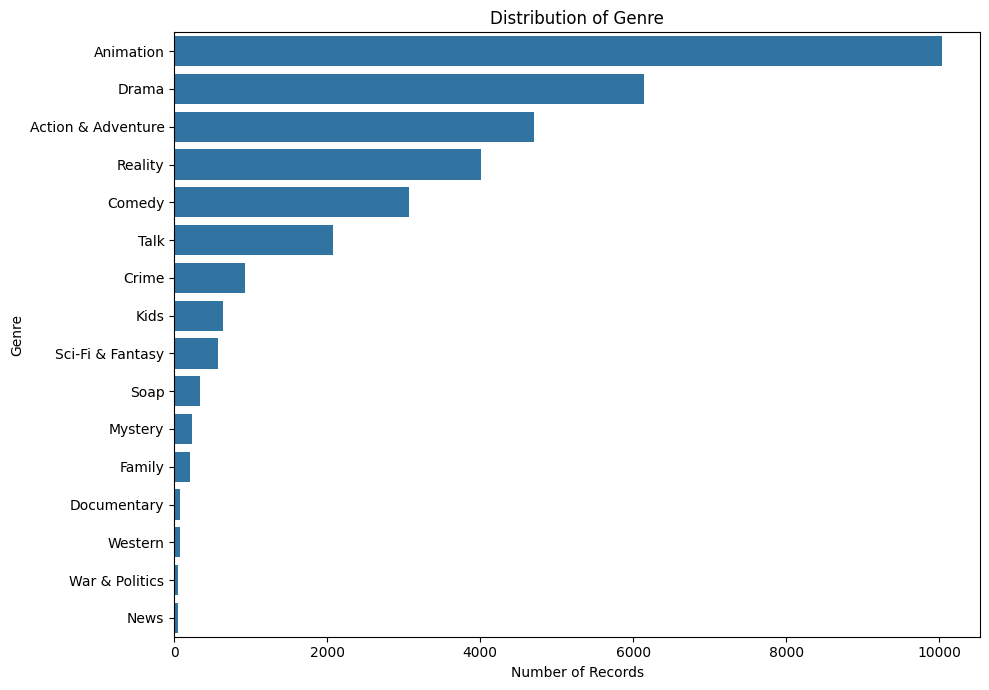

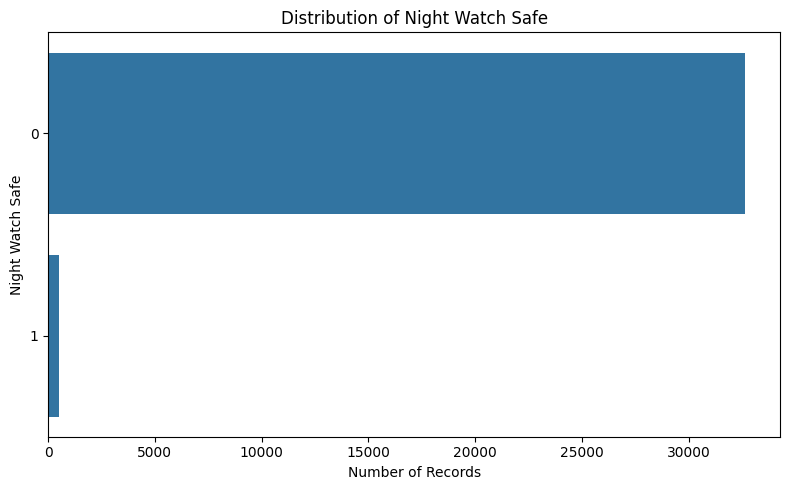

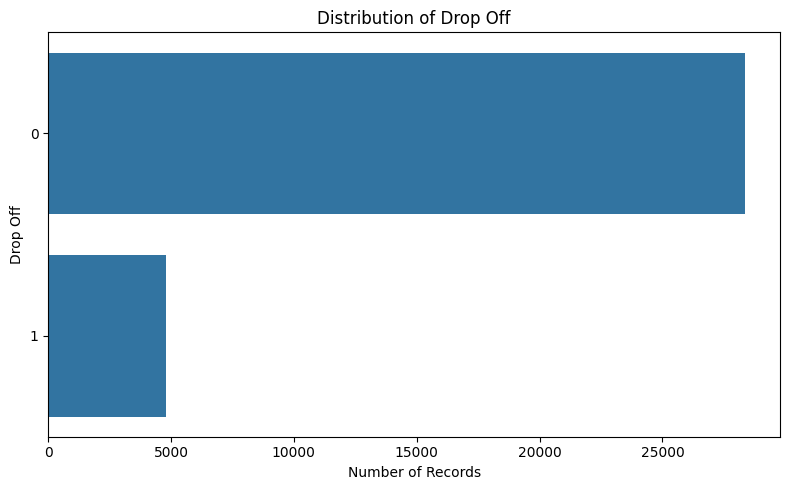

In [6]:
def plot_categorical(column, figsize=(10, 5)):
    plt.figure(figsize=figsize)
    
    order = df[column].value_counts().index
    
    sns.countplot(
        data=df,
        y=column,
        order=order
    )
    
    plt.title(f'Distribution of {column.replace("_", " ").title()}')
    plt.xlabel('Number of Records')
    plt.ylabel(column.replace("_", " ").title())
    plt.tight_layout()
    plt.show()

plot_categorical('platform', figsize=(12, 8))
plot_categorical('retention_risk')
plot_categorical('genre', figsize=(10, 7))
plot_categorical('night_watch_safe', figsize=(8, 5))
plot_categorical('drop_off', figsize=(8, 5))

But for dialogue_density, use a different plot
Because it has only 3 categories:also attention_required:

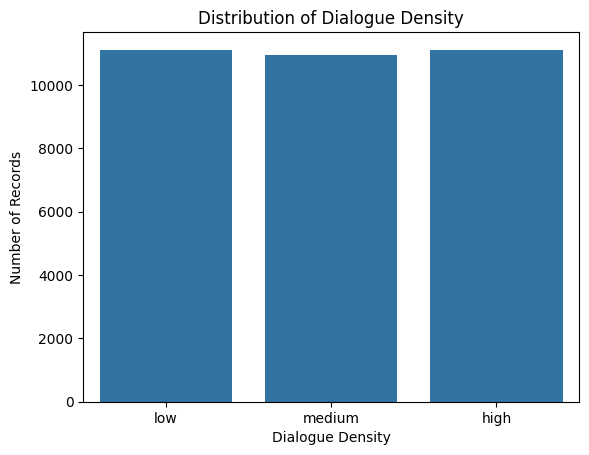

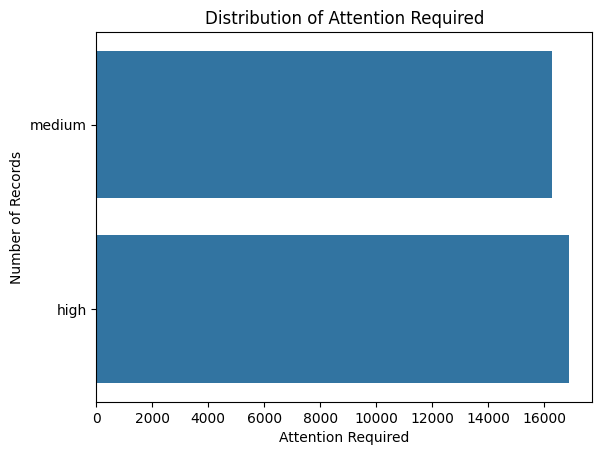

In [7]:
sns.countplot(
    data=df,
    x='dialogue_density',
    order=['low', 'medium', 'high']
)

plt.title('Distribution of Dialogue Density')
plt.xlabel('Dialogue Density')
plt.ylabel('Number of Records')
plt.show()

sns.countplot(data=df,y='attention_required',order=['medium','high'])
plt.title('Distribution of Attention Required')
plt.xlabel('Attention Required')
plt.ylabel('Number of Records')
plt.show()

UNIVARIATE ANALYSIS:NUMERICAL COLUMNS

In [8]:
df[numerical_eda_cols].describe()

,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,visual_intensity,avg_watch_percentage,pause_count,rewind_count,skip_intro,cognitive_load,drop_off_probability
count,33171.000000,33171.0,33171.000000,33171.000000,33171.000000,33171.000000,33171.000000,33171.000000,33171.000000,33171.000000,33171.000000,33171.000000,33171.000000
mean,2000.739743,1.0,423.718881,37.660667,5.397908,5.525158,6.009436,56.805764,3.102921,2.003497,0.493262,6.196015,0.478433
std,15.750470,0.0,557.688460,22.899741,1.230418,1.730098,1.994370,12.577000,1.866938,1.548391,0.499962,1.322146,0.107382
min,1952.000000,1.0,1.000000,1.000000,3.000000,3.000000,3.000000,13.000000,0.000000,0.000000,0.000000,4.000000,0.120000
25%,1992.000000,1.0,27.000000,24.000000,4.000000,4.000000,4.000000,48.000000,2.000000,1.000000,0.000000,5.000000,0.400000
50%,2004.000000,1.0,178.000000,33.000000,5.000000,6.000000,6.000000,57.000000,3.000000,2.000000,0.000000,7.000000,0.471000
75%,2012.000000,1.0,611.000000,49.000000,6.000000,7.000000,8.000000,66.000000,4.000000,3.000000,1.000000,7.000000,0.553000
max,2025.000000,1.0,2650.000000,1225.000000,8.000000,10.000000,9.000000,100.000000,10.000000,8.000000,1.000000,9.000000,0.831000


In [9]:
numerical_eda_cols = [
    'release_year',
    'episode_number',
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'avg_watch_percentage',
    'pause_count',
    'rewind_count',
    'cognitive_load',
    'drop_off_probability'
]
binary_cols = [
    'skip_intro'
]
exclude_cols = [
    'season_number'
]

In [10]:
def plot_numerical_distribution(column, figsize=(8, 5)):
    plt.figure(figsize=figsize)
    
    sns.histplot(
        data=df,
        x=column,
        kde=True
    )
    
    plt.title(f'Distribution of {column.replace("_", " ").title()}')
    plt.xlabel(column.replace("_", " ").title())
    plt.ylabel('Frequency')
    
    plt.tight_layout()
    plt.show()

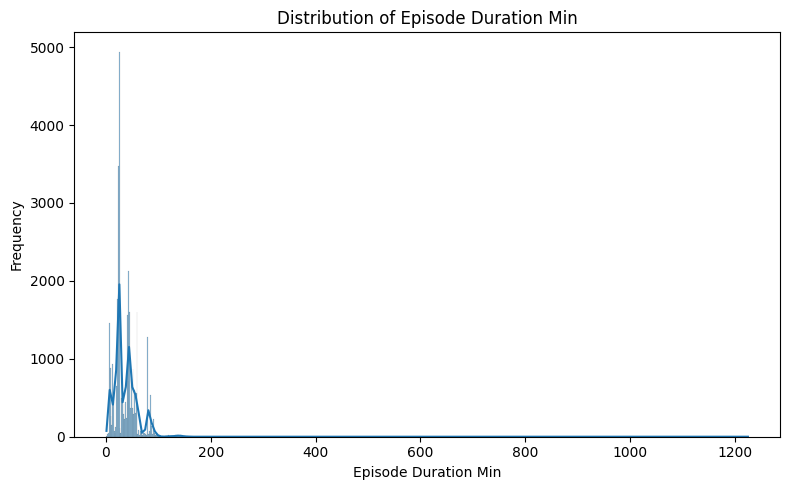

In [11]:
plot_numerical_distribution('episode_duration_min')

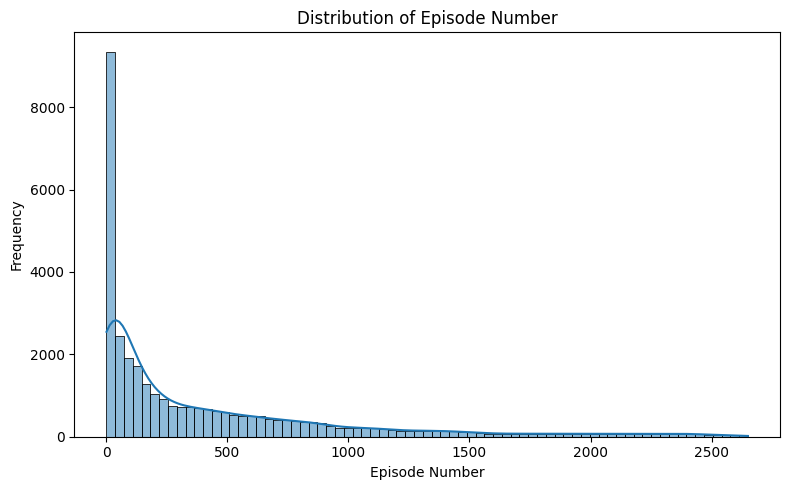

In [12]:
plot_numerical_distribution('episode_number')


In [13]:
def plot_numerical_boxplot(column, figsize=(8, 3)):
    plt.figure(figsize=figsize)
    
    sns.boxplot(
        data=df,
        x=column
    )
    
    plt.title(f'Boxplot of {column.replace("_", " ").title()}')
    plt.xlabel(column.replace("_", " ").title())
    
    plt.tight_layout()
    plt.show()

In [14]:
df['season_number'].nunique()
df[numerical_eda_cols].nunique()

release_year              65
episode_number          2650
episode_duration_min     154
pacing_score               6
hook_strength              8
visual_intensity           7
avg_watch_percentage      84
pause_count               11
rewind_count               9
cognitive_load             5
drop_off_probability     610
dtype: int64

In [15]:
df['episode_duration_min'].nlargest(10)

5260     1225
20676     170
20670     162
893       161
891       160
20678     159
904       157
20672     156
20684     156
902       155
Name: episode_duration_min, dtype: int64

In [16]:
df.loc[
    df['episode_duration_min'].nlargest(10).index,
    ['title', 'platform', 'genre', 'release_year',
     'season_number', 'episode_number', 'episode_duration_min']
]

,title,platform,genre,release_year,season_number,episode_number,episode_duration_min
5260,Doraemon,Hulu,Action & Adventure,2005,1,238,1225
20676,6 of Us,Netflix,Drama,2024,1,18,170
20670,6 of Us,Netflix,Drama,2024,1,12,162
893,Golden Boy,Disney+,Family,2022,1,23,161
891,Golden Boy,Disney+,Family,2022,1,21,160
20678,6 of Us,Netflix,Drama,2024,1,20,159
904,Golden Boy,Disney+,Family,2022,1,34,157
20672,6 of Us,Netflix,Drama,2024,1,14,156
20684,6 of Us,Netflix,Drama,2024,1,26,156
902,Golden Boy,Disney+,Family,2022,1,32,155


In [17]:
(df['episode_duration_min'] > 170).sum()

1

In [18]:
df[df['episode_duration_min'] > 170][
    ['title', 'episode_duration_min']
].sort_values(
    'episode_duration_min',
    ascending=False
).head(20)

,title,episode_duration_min
5260,Doraemon,1225


In [19]:
df[df['title'] == 'Doraemon'][
    ['episode_number', 'episode_duration_min']
].sort_values('episode_number')

,episode_number,episode_duration_min
3903,1,7
5023,1,12
5024,2,12
3904,2,7
3905,3,7
...,...,...
6463,1443,12
6464,1444,46
6465,1445,36
6466,1446,47


In [20]:
df[df['title'] == 'Doraemon']['episode_duration_min'].describe()

count    1681.000000
mean       23.123141
std        33.597030
min         6.000000
25%        12.000000
50%        12.000000
75%        35.000000
max      1225.000000
Name: episode_duration_min, dtype: float64

In [21]:
df[
    (df['title'] == 'Doraemon') &
    (df['episode_number'].between(230, 245))
][
    ['episode_number', 'episode_duration_min']
].sort_values('episode_number')

,episode_number,episode_duration_min
4132,230,6
5252,230,25
4133,231,6
5253,231,12
4134,232,6
5254,232,12
4135,233,6
5255,233,12
5256,234,12
4136,234,6


In [22]:
Q1 = df['episode_duration_min'].quantile(0.25)
Q3 = df['episode_duration_min'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

print(
    "Number of potential outliers:",
    ((df['episode_duration_min'] < lower_bound) |
     (df['episode_duration_min'] > upper_bound)).sum()
)

Q1: 24.0
Q3: 49.0
IQR: 25.0
Lower Bound: -13.5
Upper Bound: 86.5
Number of potential outliers: 852


In [23]:
df[df['episode_duration_min'] > upper_bound][
    ['title', 'episode_number', 'episode_duration_min']
].sort_values(
    'episode_duration_min',
    ascending=False
).head(20)

,title,episode_number,episode_duration_min
5260,Doraemon,238,1225
20676,6 of Us,18,170
20670,6 of Us,12,162
893,Golden Boy,23,161
891,Golden Boy,21,160
20678,6 of Us,20,159
904,Golden Boy,34,157
20672,6 of Us,14,156
20684,6 of Us,26,156
902,Golden Boy,32,155


In [24]:
outlier_count = (
    (df['episode_duration_min'] < lower_bound) |
    (df['episode_duration_min'] > upper_bound)
).sum()

outlier_percentage = (outlier_count / len(df)) * 100

print("Potential outliers:", outlier_count)
print(f"Percentage of potential outliers: {outlier_percentage:.2f}%")

Potential outliers: 852
Percentage of potential outliers: 2.57%


In [25]:
# Which shows are responsible for most of the long-duration episodes?
df[df['episode_duration_min'] > 86.5]['title'].value_counts().head(20)

title
Men on a Mission                  279
Running Man                       240
Leyla                              39
Golden Boy                         36
Boundless Love                     34
6 of Us                            28
Far Away                           28
KuruluÅŸ Osman                     27
Hello Saturday                     23
Esref Ruya                         13
Forbidden Fruit                    12
Amazing Night                      10
Detective Conan                    10
Winds of Love                       8
Who's the Murderer                  6
Midsomer Murders                    5
Home Alone                          5
Y'a que la vÃ©ritÃ© qui compte      5
Radio Star                          5
Vera                                4
Name: count, dtype: int64

In [26]:
# That will tell us the distribution of these long episodes.
df[df['episode_duration_min'] > 86.5]['episode_duration_min'].describe()

count     852.000000
mean      104.605634
std        43.685602
min        87.000000
25%        90.000000
50%        92.000000
75%       120.000000
max      1225.000000
Name: episode_duration_min, dtype: float64

In [27]:
# "Show me the complete record having the maximum episode duration."
extreme_duration = df[df['episode_duration_min'] == df['episode_duration_min'].max()]

extreme_duration[
    ['title', 'platform', 'genre', 'release_year',
     'season_number', 'episode_number', 'episode_duration_min']
]

,title,platform,genre,release_year,season_number,episode_number,episode_duration_min
5260,Doraemon,Hulu,Action & Adventure,2005,1,238,1225


In [28]:
# Step 2 — Compare it with nearby Doraemon episodes
df[
    (df['title'] == 'Doraemon') &
    (df['episode_number'].between(230, 245))
][
    ['episode_number', 'episode_duration_min']
].sort_values('episode_number')

,episode_number,episode_duration_min
4132,230,6
5252,230,25
4133,231,6
5253,231,12
4134,232,6
5254,232,12
4135,233,6
5255,233,12
5256,234,12
4136,234,6


In [29]:
# Create a flag instead of deleting it
df['duration_extreme_flag'] = (
    df['episode_duration_min'] > 300
)
df[df['duration_extreme_flag']]

,show_id,title,platform,genre,release_year,season_number,episode_number,episode_duration_min,pacing_score,hook_strength,...,rewind_count,skip_intro,cognitive_load,attention_required,night_watch_safe,drop_off,drop_off_probability,retention_risk,dataset_version,duration_extreme_flag
5260,65733,Doraemon,Hulu,Action & Adventure,2005,1,238,1225,5,5,...,1,1,7,high,0,0,0.559,medium,v1.0,True


In [30]:
# Check how many extreme records exist
df['duration_extreme_flag'].value_counts()

duration_extreme_flag
False    33170
True         1
Name: count, dtype: int64

In [31]:
# This lets us see whether 1225 is the only truly extreme value or whether there are several.
df[df['duration_extreme_flag']][
    ['title', 'episode_number', 'episode_duration_min']
]

,title,episode_number,episode_duration_min
5260,Doraemon,238,1225


In [32]:
# Since duration_extreme_flag was created by us, it is not part of the original dataset.

# So I would not keep this column in your main df while continuing the EDA.
df = df.drop(columns='duration_extreme_flag')

3.Pacing score analysis

In [33]:
df['pacing_score'].value_counts().sort_index()

pacing_score
3    1550
4    7562
5    8340
6    8358
7    6580
8     781
Name: count, dtype: int64

In [34]:
df['pacing_score'].value_counts(normalize=True).sort_index() * 100

pacing_score
3     4.672756
4    22.797021
5    25.142444
6    25.196708
7    19.836604
8     2.354466
Name: proportion, dtype: float64

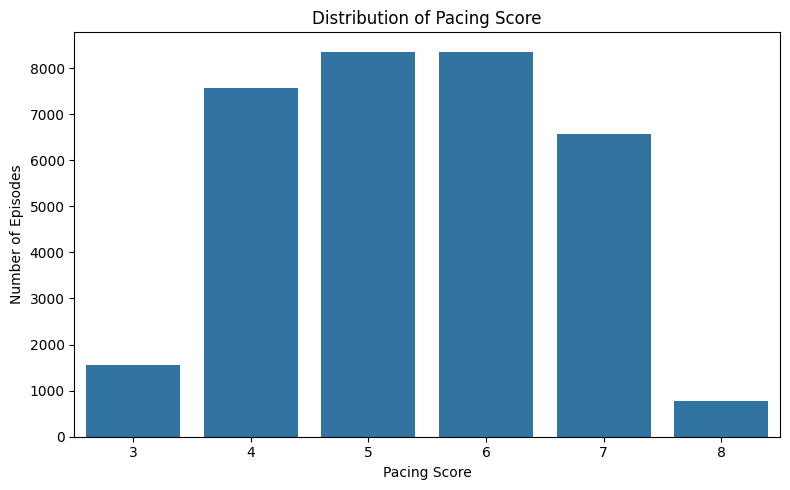

In [35]:
# Visualizing the pacing score with a countplot cuz it has discrete values
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='pacing_score',
    order=sorted(df['pacing_score'].unique())
)

plt.title('Distribution of Pacing Score')
plt.xlabel('Pacing Score')
plt.ylabel('Number of Episodes')

plt.tight_layout()
plt.show()

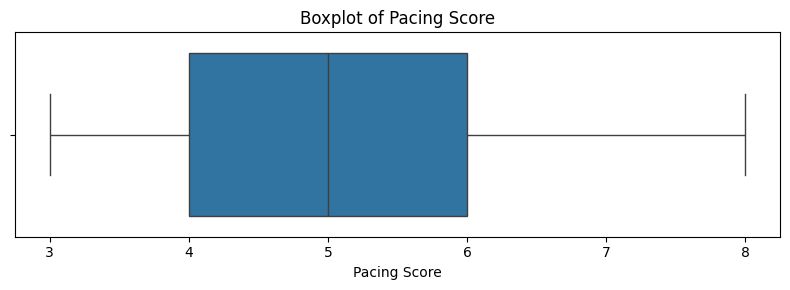

In [36]:
# Check for possible outliers



plt.figure(figsize=(8, 3))

sns.boxplot(
    data=df,
    x='pacing_score'
)

plt.title('Boxplot of Pacing Score')
plt.xlabel('Pacing Score')

plt.tight_layout()
plt.show()

5.hook_strength analysis

In [37]:
df['hook_strength'].value_counts().sort_index()

hook_strength
3     5515
4     5430
5     5484
6     5606
7     5423
8     5527
9       83
10     103
Name: count, dtype: int64

In [38]:
df['hook_strength'].value_counts(normalize=True).sort_index() * 100

hook_strength
3     16.625968
4     16.369721
5     16.532513
6     16.900304
7     16.348618
8     16.662145
9      0.250219
10     0.310512
Name: proportion, dtype: float64

In [39]:
# inspecting col 9,10
df[df['hook_strength'] >= 9][
    ['title', 'genre', 'platform', 'hook_strength']
].head(20)

,title,genre,platform,hook_strength
83,Game of Thrones,Sci-Fi & Fantasy,HBO Max,9
93,The Boys from Brazil: Rise of the Bolsonaros,Documentary,Disney+,9
96,The Simpsons,Family,Disney+,10
109,The Rookie,Crime,Hulu,10
152,Record of Ragnarok,Action & Adventure,Netflix,10
197,Law & Order,Crime,Hulu,10
219,Family Guy,Animation,Hulu,10
226,Breaking Bad,Drama,Netflix,10
255,The Blacklist,Drama,Netflix,10
299,Esref Ruya,Drama,Disney+,10


In [40]:
df[df['hook_strength'] >= 9]['title'].value_counts().head(20)

title
Doctor Who                                      2
Sniper Butterfly                                2
Game of Thrones                                 1
The Boys from Brazil: Rise of the Bolsonaros    1
The Simpsons                                    1
The Rookie                                      1
Record of Ragnarok                              1
Law & Order                                     1
Family Guy                                      1
Breaking Bad                                    1
The Blacklist                                   1
Esref Ruya                                      1
The War Between the Land and the Sea            1
The Witcher                                     1
Homeland                                        1
The Daily Show                                  1
The Boys                                        1
The Walking Dead                                1
Wednesday                                       1
DinastÃ­a Casillas                          

In [41]:
df['hook_strength'].describe()

count    33171.000000
mean         5.525158
std          1.730098
min          3.000000
25%          4.000000
50%          6.000000
75%          7.000000
max         10.000000
Name: hook_strength, dtype: float64

In [42]:
Q1 = df['hook_strength'].quantile(0.25)
Q3 = df['hook_strength'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)

Q1: 4.0
Q3: 7.0
IQR: 3.0
Lower bound: -0.5
Upper bound: 11.5


6.Visual_intensity

In [43]:
# This one has only 7 unique values, so we'll use almost the exact same workflow:
df['visual_intensity'].value_counts().sort_index()

visual_intensity
3    4717
4    4608
5    4743
6    4922
7    4640
8    4840
9    4701
Name: count, dtype: int64

In [44]:
df['visual_intensity'].value_counts(normalize=True).sort_index() * 100

visual_intensity
3    14.220253
4    13.891652
5    14.298634
6    14.838262
7    13.988122
8    14.591058
9    14.172018
Name: proportion, dtype: float64

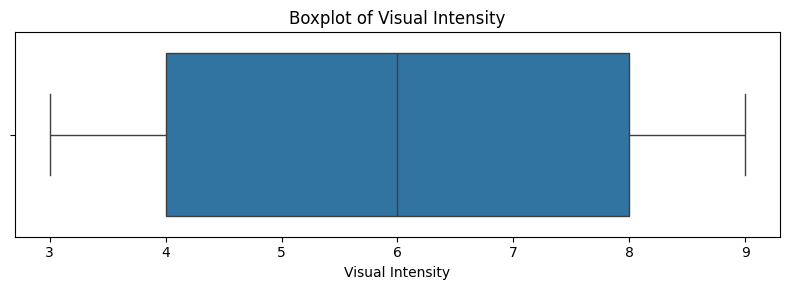

In [45]:
plt.figure(figsize=(8, 3))

sns.boxplot(
    data=df,
    x='visual_intensity'
)

plt.title('Boxplot of Visual Intensity')
plt.xlabel('Visual Intensity')

plt.tight_layout()
plt.show()

7.avg_watch_percentage

In [46]:
df['avg_watch_percentage'].describe()

count    33171.000000
mean        56.805764
std         12.577000
min         13.000000
25%         48.000000
50%         57.000000
75%         66.000000
max        100.000000
Name: avg_watch_percentage, dtype: float64

In [47]:
df['avg_watch_percentage'].nunique()

84

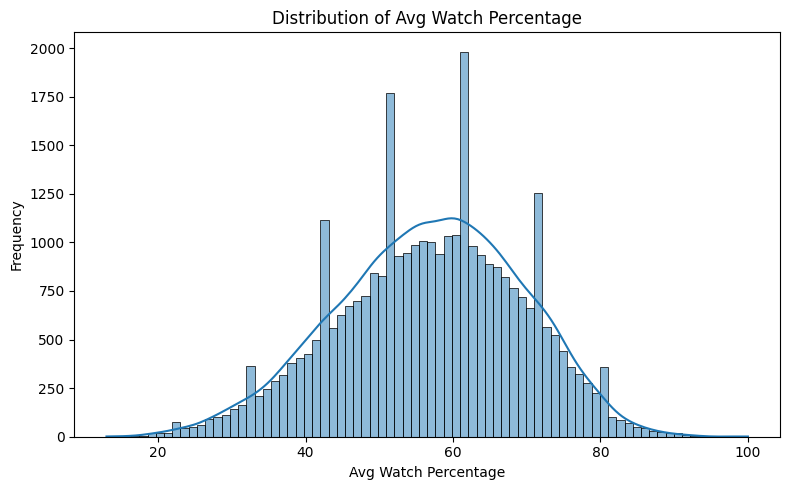

In [48]:
plot_numerical_distribution('avg_watch_percentage')

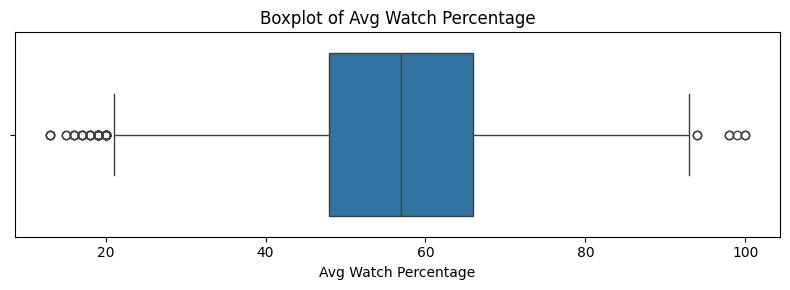

In [49]:
plot_numerical_boxplot('avg_watch_percentage')

In [50]:
# How many episodes have average watch percentage below 21% or above 93%?
Q1 = df['avg_watch_percentage'].quantile(0.25)
Q3 = df['avg_watch_percentage'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_count = (
    (df['avg_watch_percentage'] < lower_bound) |
    (df['avg_watch_percentage'] > upper_bound)
).sum()

print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outliers:", outlier_count)
print("Percentage:", (outlier_count / len(df)) * 100)

IQR: 18.0
Lower bound: 21.0
Upper bound: 93.0
Potential outliers: 61
Percentage: 0.18389557143287813


In [51]:
# This will show us the 61 potential outlier observations.
df[
    (df['avg_watch_percentage'] < lower_bound) |
    (df['avg_watch_percentage'] > upper_bound)
][
    ['title', 'platform', 'genre', 'avg_watch_percentage']
].sort_values('avg_watch_percentage')

,title,platform,genre,avg_watch_percentage
21033,Dreams of Liberty,Hulu,Drama,13
27246,RadhaKrishn,Disney+,Drama,13
14714,A Kindred Spirit,Hulu,Drama,13
21243,Dreams of Liberty,Hulu,Drama,15
10680,Sazae-san,Netflix,Animation,15
...,...,...,...,...
13312,Buffy the Vampire Slayer,Hulu,Sci-Fi & Fantasy,98
197,Law & Order,Hulu,Crime,98
1840,Young Sheldon,Netflix,Comedy,99
25672,2 Broke Girls,Netflix,Comedy,100


8.Pause Count

In [52]:
df['pause_count'].value_counts().sort_index()

pause_count
0     1782
1     4929
2     7052
3     7012
4     5375
5     3461
6     1930
7      932
8      429
9      173
10      96
Name: count, dtype: int64

In [53]:
df['pause_count'].value_counts(normalize=True).sort_index() * 100

pause_count
0      5.372162
1     14.859365
2     21.259534
3     21.138947
4     16.203913
5     10.433813
6      5.818335
7      2.809683
8      1.293298
9      0.521540
10     0.289409
Name: proportion, dtype: float64

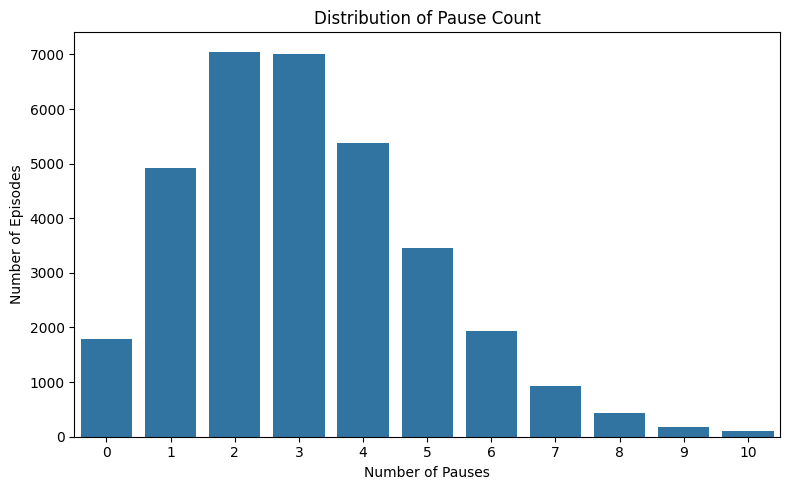

In [54]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='pause_count',
    order=sorted(df['pause_count'].unique())
)

plt.title('Distribution of Pause Count')
plt.xlabel('Number of Pauses')
plt.ylabel('Number of Episodes')

plt.tight_layout()
plt.show()

9.rewind_count

In [55]:
df['rewind_count'].value_counts().sort_index()

rewind_count
0    5476
1    8741
2    8122
3    5515
4    3014
5    1387
6     576
7     239
8     101
Name: count, dtype: int64

In [56]:
df['rewind_count'].value_counts(normalize=True).sort_index() * 100

rewind_count
0    16.508396
1    26.351331
2    24.485243
3    16.625968
4     9.086250
5     4.181363
6     1.736457
7     0.720509
8     0.304483
Name: proportion, dtype: float64

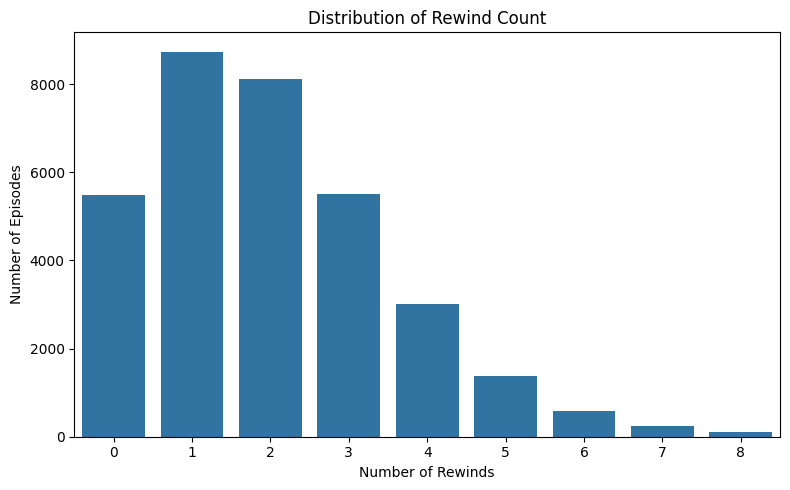

In [57]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='rewind_count',
    order=sorted(df['rewind_count'].unique())
)

plt.title('Distribution of Rewind Count')
plt.xlabel('Number of Rewinds')
plt.ylabel('Number of Episodes')

plt.tight_layout()
plt.show()

In [58]:
df['cognitive_load'].value_counts().sort_index()

cognitive_load
4      527
5    15512
6      254
7    13783
9     3095
Name: count, dtype: int64

In [59]:
df['cognitive_load'].value_counts(normalize=True).sort_index() * 100

cognitive_load
4     1.588737
5    46.763739
6     0.765729
7    41.551355
9     9.330439
Name: proportion, dtype: float64

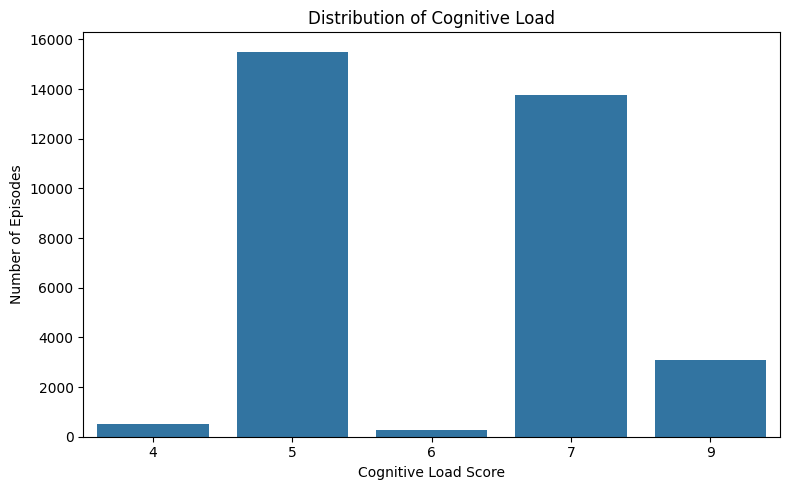

In [60]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='cognitive_load',
    order=sorted(df['cognitive_load'].unique())
)

plt.title('Distribution of Cognitive Load')
plt.xlabel('Cognitive Load Score')
plt.ylabel('Number of Episodes')

plt.tight_layout()
plt.show()

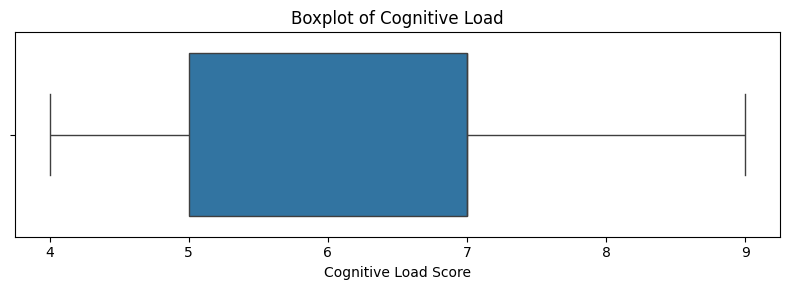

In [61]:
plt.figure(figsize=(8, 3))

sns.boxplot(
    data=df,
    x='cognitive_load'
)

plt.title('Boxplot of Cognitive Load')
plt.xlabel('Cognitive Load Score')

plt.tight_layout()
plt.show()

10.drop_off_probability

In [62]:
df['drop_off_probability'].describe()

count    33171.000000
mean         0.478433
std          0.107382
min          0.120000
25%          0.400000
50%          0.471000
75%          0.553000
max          0.831000
Name: drop_off_probability, dtype: float64

In [63]:
df['drop_off_probability'].nunique()

610

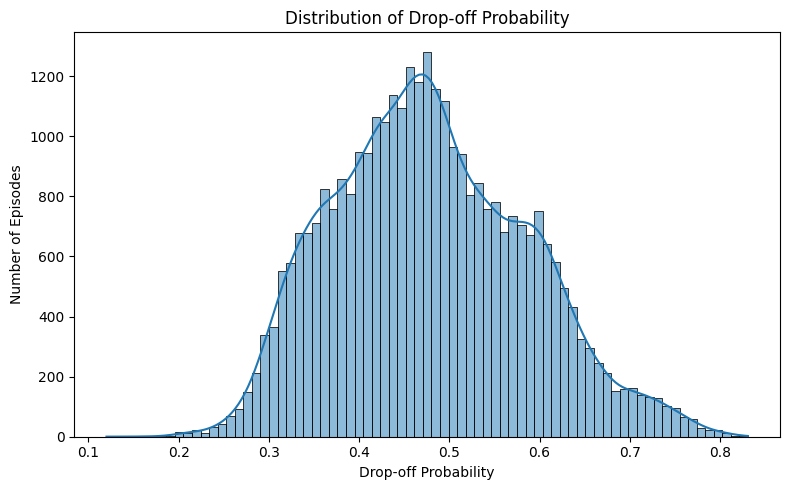

In [64]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='drop_off_probability',
    kde=True
)

plt.title('Distribution of Drop-off Probability')
plt.xlabel('Drop-off Probability')
plt.ylabel('Number of Episodes')

plt.tight_layout()
plt.show()

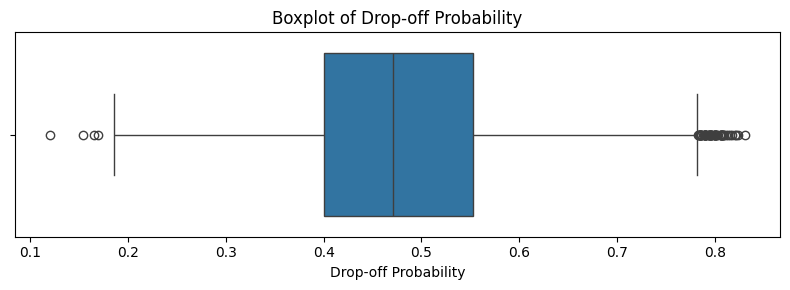

In [65]:
plt.figure(figsize=(8, 3))

sns.boxplot(
    data=df,
    x='drop_off_probability'
)

plt.title('Boxplot of Drop-off Probability')
plt.xlabel('Drop-off Probability')

plt.tight_layout()
plt.show()

In [66]:
Q1 = df['drop_off_probability'].quantile(0.25)
Q3 = df['drop_off_probability'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 0.4
Q3: 0.553
IQR: 0.15300000000000002
Lower Bound: 0.17049999999999998
Upper Bound: 0.7825000000000001


In [67]:
outliers = df[
    (df['drop_off_probability'] < lower_bound) |
    (df['drop_off_probability'] > upper_bound)
]

print("Number of potential outliers:", len(outliers))
print("Percentage:", len(outliers) / len(df) * 100)

Number of potential outliers: 68
Percentage: 0.2049983419251756


In [68]:
outliers[['title', 'platform', 'genre', 'drop_off_probability']].sort_values(
    'drop_off_probability',
    ascending=False
).head(20)

,title,platform,genre,drop_off_probability
20822,Blood Flowers,Hulu,Drama,0.831
6280,Doraemon,Hulu,Action & Adventure,0.824
21860,Pleasant Goat and Big Big Wolf,Netflix,Animation,0.822
15252,A Kindred Spirit,Hulu,Drama,0.821
31170,Show! Music Core,Kocowa Amazon Channel,Reality,0.817
14403,A Kindred Spirit,Hulu,Drama,0.815
31394,Station 19,Hulu,Drama,0.813
25255,This Is Us,Disney+,Drama,0.811
32169,CID,Netflix,Action & Adventure,0.809
21243,Dreams of Liberty,Hulu,Drama,0.808


In [69]:
outliers[['title', 'platform', 'genre', 'drop_off_probability']].sort_values(
    'drop_off_probability'
).head(20)

,title,platform,genre,drop_off_probability
16149,30 Rock,Prime Video,Comedy,0.120
1840,Young Sheldon,Netflix,Comedy,0.154
25672,2 Broke Girls,Netflix,Comedy,0.165
13312,Buffy the Vampire Slayer,Hulu,Sci-Fi & Fantasy,0.169
6544,"Gute Zeiten, schlechte Zeiten",Netflix,Drama,0.783
18172,Shin Chan,Netflix,Animation,0.784
22652,Radio Star,OnDemandKorea,Talk,0.784
14713,A Kindred Spirit,Hulu,Drama,0.784
17780,Shin Chan,Netflix,Animation,0.785
15281,Ranma1/2,Netflix,Animation,0.785


11.release_year

In [70]:
df['release_year'].value_counts().sort_index()

release_year
1952      6
1955    199
1957     39
1959     32
1960     39
       ... 
2021    141
2022    510
2023    670
2024    715
2025    698
Name: count, Length: 65, dtype: int64

In [71]:
df['release_year'].describe()

count    33171.000000
mean      2000.739743
std         15.750470
min       1952.000000
25%       1992.000000
50%       2004.000000
75%       2012.000000
max       2025.000000
Name: release_year, dtype: float64

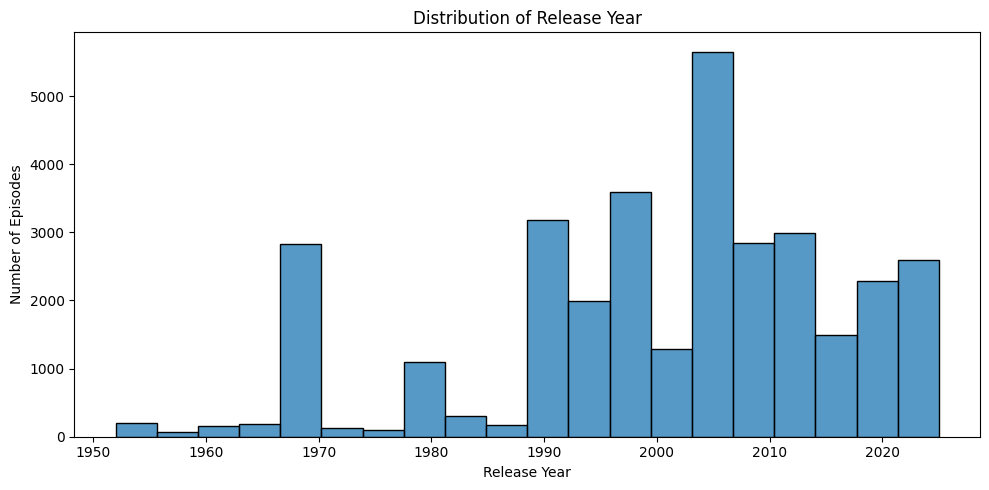

In [72]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x='release_year',
    bins=20
)

plt.title('Distribution of Release Year')
plt.xlabel('Release Year')
plt.ylabel('Number of Episodes')

plt.tight_layout()
plt.show()

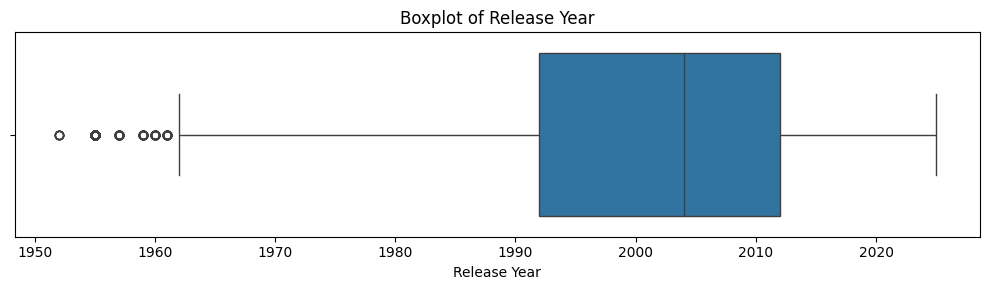

In [73]:
plt.figure(figsize=(10, 3))

sns.boxplot(
    data=df,
    x='release_year'
)

plt.title('Boxplot of Release Year')
plt.xlabel('Release Year')

plt.tight_layout()
plt.show()

In [74]:
Q1 = df['release_year'].quantile(0.25)
Q3 = df['release_year'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)

Q1: 1992.0
Q3: 2012.0
IQR: 20.0
Lower Bound: 1962.0
Upper Bound: 2042.0


In [75]:
old_content = df[df['release_year'] < 1962]

print("Number of records:", len(old_content))
print("Percentage:", len(old_content) / len(df) * 100)

Number of records: 351
Percentage: 1.058153206113774


In [76]:
old_content['release_year'].value_counts().sort_index()

release_year
1952      6
1955    199
1957     39
1959     32
1960     39
1961     36
Name: count, dtype: int64

12.skip_intro

In [77]:
df['skip_intro'].value_counts().sort_index()

skip_intro
0    16809
1    16362
Name: count, dtype: int64

In [78]:
df['skip_intro'].value_counts(normalize=True).sort_index() * 100

skip_intro
0    50.673781
1    49.326219
Name: proportion, dtype: float64

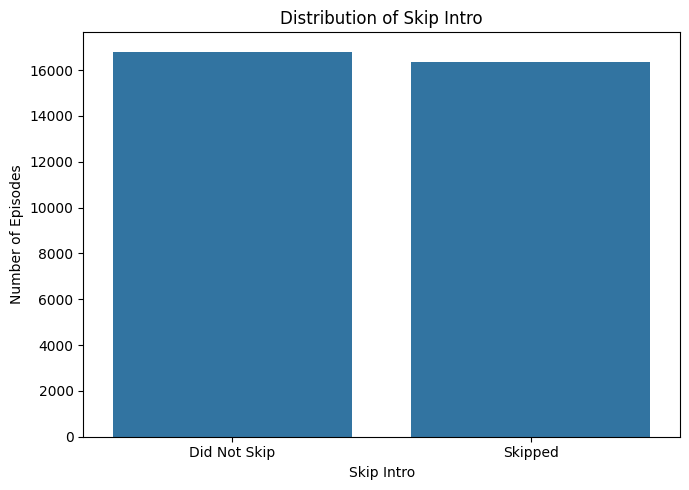

In [79]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='skip_intro',
    order=sorted(df['skip_intro'].unique())
)

plt.title('Distribution of Skip Intro')
plt.xlabel('Skip Intro')
plt.ylabel('Number of Episodes')

plt.xticks(
    [0, 1],
    ['Did Not Skip', 'Skipped']
)

plt.tight_layout()
plt.show()

BIVARIATE ANALYSIS

avg_watch_percentage vs drop_off_probability
Do episodes that viewers watch for a higher percentage tend to have a lower drop-off probability?

In [80]:
print(df['avg_watch_percentage'].min())
print(df['avg_watch_percentage'].max())

print(df['drop_off_probability'].min())
print(df['drop_off_probability'].max())
print(df[['avg_watch_percentage', 'drop_off_probability']].head(10))

13
100
0.12
0.831
   avg_watch_percentage  drop_off_probability
0                    39                 0.649
1                    55                 0.473
2                    46                 0.583
3                    50                 0.520
4                    35                 0.638
5                    53                 0.506
6                    65                 0.407
7                    55                 0.477
8                    72                 0.321
9                    45                 0.532


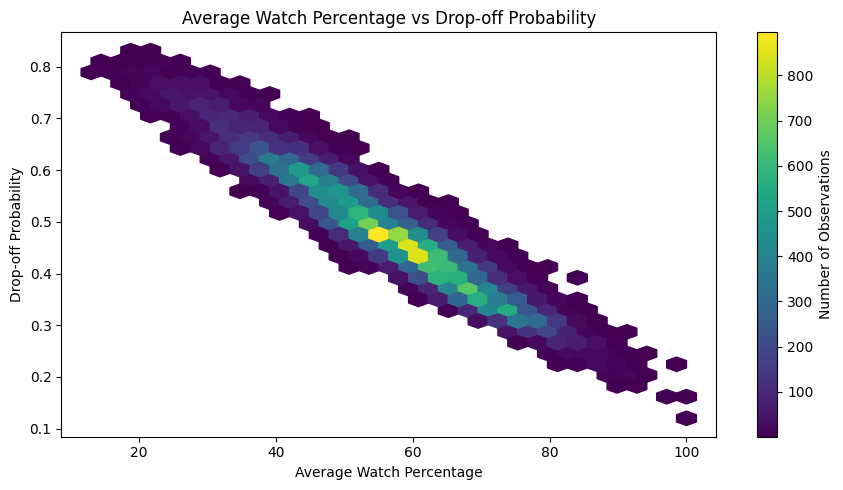

In [81]:
plt.figure(figsize=(9, 5))

plt.hexbin(
    df['avg_watch_percentage'],
    df['drop_off_probability'],
    gridsize=30,
    mincnt=1
)

plt.colorbar(label='Number of Observations')

plt.title('Average Watch Percentage vs Drop-off Probability')
plt.xlabel('Average Watch Percentage')
plt.ylabel('Drop-off Probability')

plt.tight_layout()
plt.show()

In [82]:
correlation = df['avg_watch_percentage'].corr(
    df['drop_off_probability']
)

print("Correlation:", correlation)

Correlation: -0.9573285289457164


episode_duration_min vs avg_watch_percentage
Our question will be:
Do longer episodes tend to have lower average watch percentages?

We previously found that only one observation exceeds 300 minutes, and that observation was the suspicious 1225-minute Doraemon record.
We're not deleting it from df. We're only excluding it temporarily so it doesn't distort this particular visualization.

In [83]:
df_duration_analysis = df[
    df['episode_duration_min'] <= 300
].copy()

print("Original observations:", len(df))
print("Observations used:", len(df_duration_analysis))

Original observations: 33171
Observations used: 33170


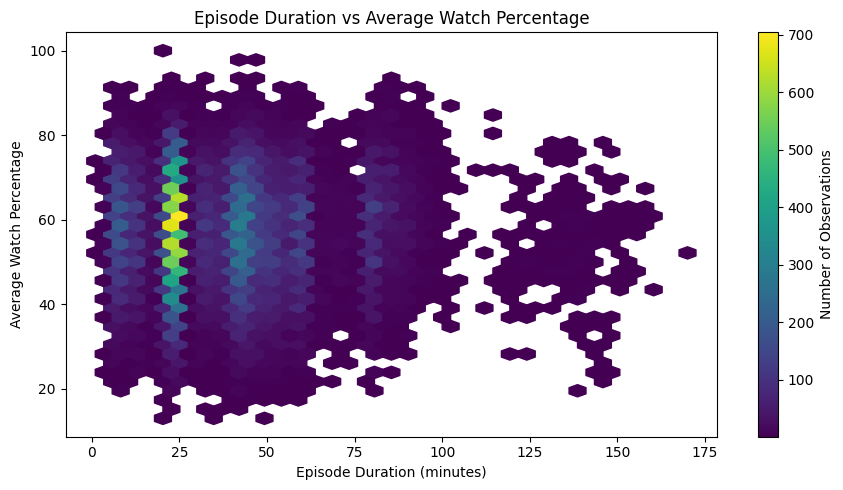

In [84]:
plt.figure(figsize=(9, 5))

plt.hexbin(
    df_duration_analysis['episode_duration_min'],
    df_duration_analysis['avg_watch_percentage'],
    gridsize=35,
    mincnt=1
)

plt.colorbar(label='Number of Observations')

plt.title('Episode Duration vs Average Watch Percentage')
plt.xlabel('Episode Duration (minutes)')
plt.ylabel('Average Watch Percentage')

plt.tight_layout()
plt.show()

In [85]:
duration_watch_corr = df_duration_analysis[
    'episode_duration_min'
].corr(
    df_duration_analysis['avg_watch_percentage']
)

print("Correlation:", duration_watch_corr)

Correlation: 0.000765506148051411


#3: episode_duration_min vs drop_off_probability.
Do longer episodes tend to have higher or lower drop-off probability?


We'll use the same filtered dataset: df_duration_analysis

This excludes only the suspicious 1225-minute observation, while keeping your original df untouched.

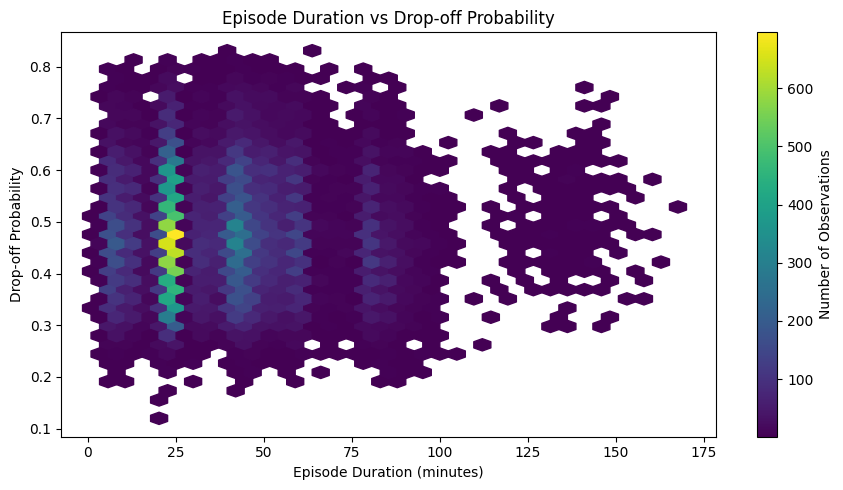

In [86]:
# Step 1 — Hexbin plot
# Since we have 33k+ observations, hexbin is again appropriate:
plt.figure(figsize=(9, 5))

plt.hexbin(
    df_duration_analysis['episode_duration_min'],
    df_duration_analysis['drop_off_probability'],
    gridsize=35,
    mincnt=1
)

plt.colorbar(label='Number of Observations')

plt.title('Episode Duration vs Drop-off Probability')
plt.xlabel('Episode Duration (minutes)')
plt.ylabel('Drop-off Probability')

plt.tight_layout()
plt.show()

In [87]:
duration_dropoff_corr = df_duration_analysis[
    'episode_duration_min'
].corr(
    df_duration_analysis['drop_off_probability']
)

print("Correlation:", duration_dropoff_corr)

Correlation: -0.0014942255368352072


#4: cognitive_load vs drop_off_probability.
🎯 Question
Do episodes with different cognitive-load scores have different drop-off probabilities?

Here, cognitive_load has only 5 observed values: 4, 5, 6, 7, 9.
So unlike our previous numerical × numerical analysis, I wouldn't use a regular scatter/hexbin as the primary plot. A boxplot is much better because it lets us compare the distribution of drop_off_probability for each cognitive-load score.

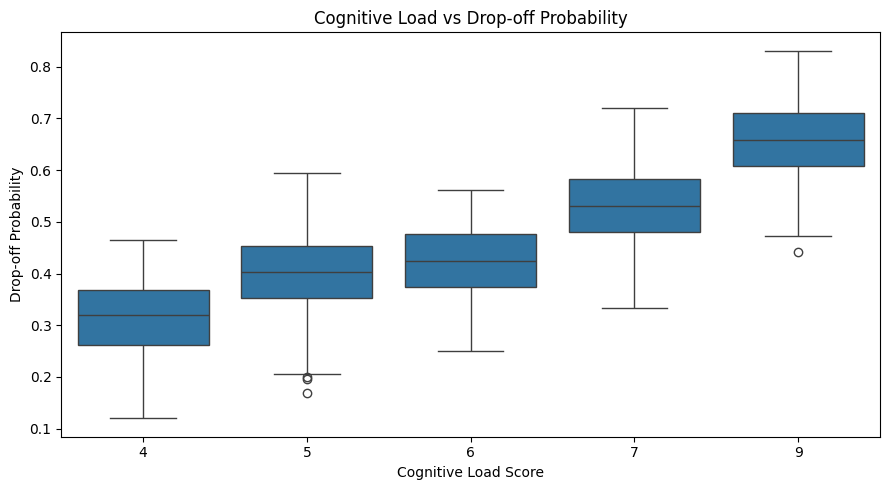

In [88]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='cognitive_load',
    y='drop_off_probability',
    order=sorted(df['cognitive_load'].unique())
)

plt.title('Cognitive Load vs Drop-off Probability')
plt.xlabel('Cognitive Load Score')
plt.ylabel('Drop-off Probability')

plt.tight_layout()
plt.show()

In [89]:
cognitive_dropoff = df.groupby(
    'cognitive_load'
)['drop_off_probability'].agg(['mean', 'median', 'count'])

print(cognitive_dropoff)

                    mean  median  count
cognitive_load                         
4               0.316554   0.319    527
5               0.402850   0.403  15512
6               0.426642   0.424    254
7               0.529948   0.531  13783
9               0.659652   0.659   3095


#5: pacing_score vs drop_off_probability.
 Question
Does the pacing of an episode appear to be associated with its predicted drop-off probability?

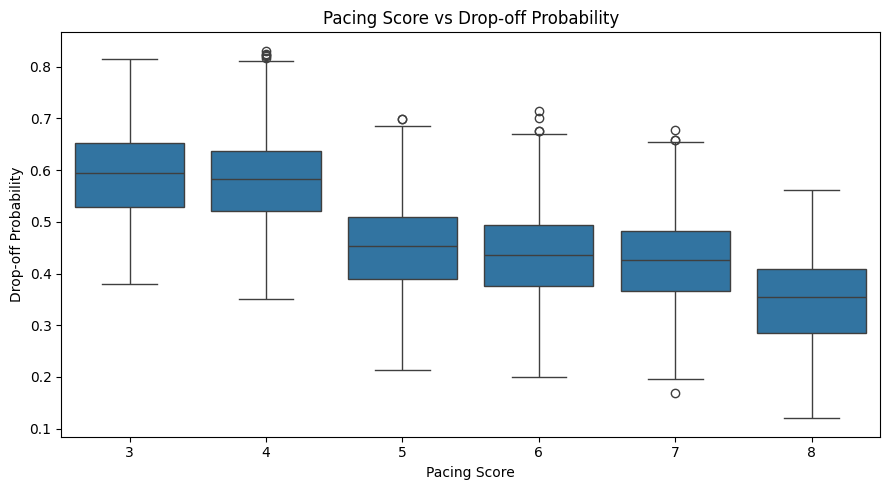

In [90]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='pacing_score',
    y='drop_off_probability',
    order=sorted(df['pacing_score'].unique())
)

plt.title('Pacing Score vs Drop-off Probability')
plt.xlabel('Pacing Score')
plt.ylabel('Drop-off Probability')

plt.tight_layout()
plt.show()

In [91]:
# Step 2 — Group statistics
pacing_dropoff = df.groupby(
    'pacing_score'
)['drop_off_probability'].agg(['mean', 'median', 'count'])

print(pacing_dropoff)

                  mean  median  count
pacing_score                         
3             0.594783   0.595   1550
4             0.582608   0.582   7562
5             0.453635   0.453   8340
6             0.439017   0.436   8358
7             0.427765   0.426   6580
8             0.352357   0.354    781


In [92]:
pacing_corr = df['pacing_score'].corr(
    df['drop_off_probability']
)

print("Correlation:", pacing_corr)

Correlation: -0.5567657333870504


#6: hook_strength vs drop_off_probability.
🎯 Question
Does stronger hook strength appear to be associated with lower drop-off probability?

hook_strength has only 8 observed scores (3–10), so again we'll treat the scores as discrete groups and use a boxplot.

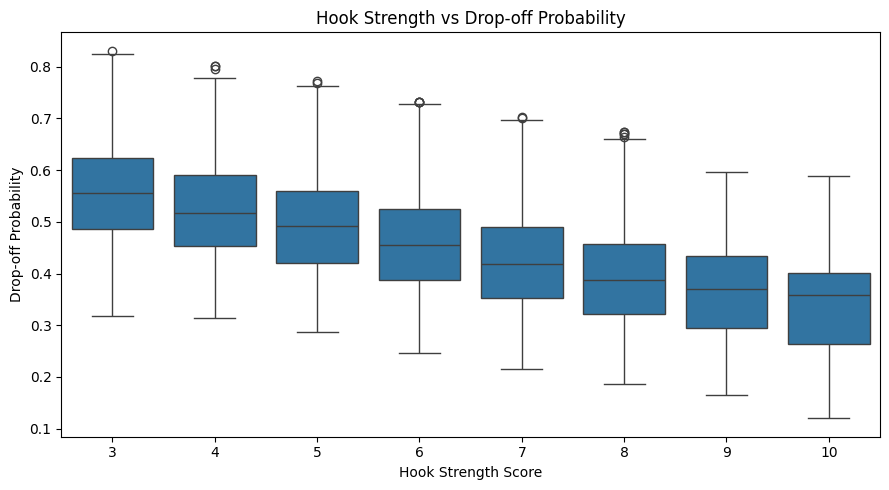

In [93]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='hook_strength',
    y='drop_off_probability',
    order=sorted(df['hook_strength'].unique())
)

plt.title('Hook Strength vs Drop-off Probability')
plt.xlabel('Hook Strength Score')
plt.ylabel('Drop-off Probability')

plt.tight_layout()
plt.show()

In [94]:
hook_dropoff = df.groupby(
    'hook_strength'
)['drop_off_probability'].agg(['mean', 'median', 'count'])

print(hook_dropoff)

                   mean  median  count
hook_strength                         
3              0.562038   0.555   5515
4              0.527755   0.518   5430
5              0.497190   0.492   5484
6              0.463001   0.455   5606
7              0.429358   0.418   5423
8              0.395874   0.387   5527
9              0.370855   0.371     83
10             0.343660   0.358    103


In [95]:
hook_corr = df['hook_strength'].corr(
    df['drop_off_probability']
)

print("Correlation:", hook_corr)

Correlation: -0.5327160869514691


#7: visual_intensity vs drop_off_probability.
🎯 Question
Does visual intensity appear to be associated with drop-off probability?
visual_intensity has only 7 discrete scores: 3–9, so we'll use the same approach as pacing_score and hook_strength:
Boxplot → group statistics → correlation → interpretation

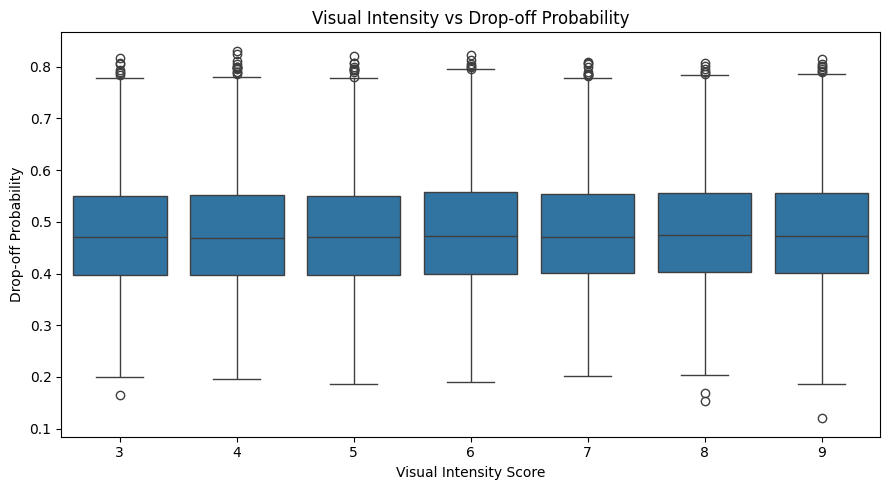

In [96]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x='visual_intensity',
    y='drop_off_probability',
    order=sorted(df['visual_intensity'].unique())
)

plt.title('Visual Intensity vs Drop-off Probability')
plt.xlabel('Visual Intensity Score')
plt.ylabel('Drop-off Probability')

plt.tight_layout()
plt.show()

In [97]:
visual_dropoff = df.groupby(
    'visual_intensity'
)['drop_off_probability'].agg(['mean', 'median', 'count'])

print(visual_dropoff)

                      mean  median  count
visual_intensity                         
3                 0.476381  0.4700   4717
4                 0.477602  0.4690   4608
5                 0.477122  0.4710   4743
6                 0.479528  0.4720   4922
7                 0.478123  0.4710   4640
8                 0.480798  0.4745   4840
9                 0.479353  0.4720   4701


In [98]:
visual_corr = df['visual_intensity'].corr(
    df['drop_off_probability']
)

print("Correlation:", visual_corr)

Correlation: 0.010889363750296388


8. genre vs drop_off_probability .Since genre categorical hai aur drop_off_probability numerical, boxplot use karenge.

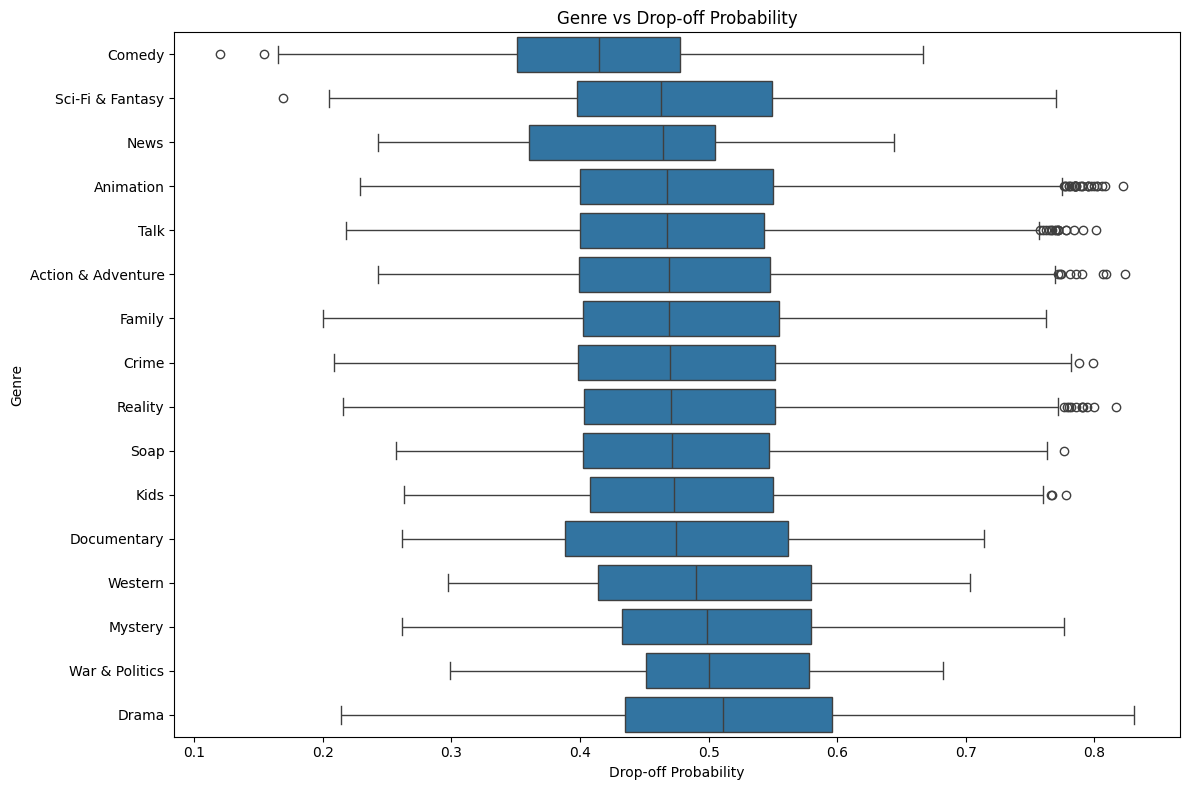

In [99]:
plt.figure(figsize=(12, 8))

genre_order = (
    df.groupby('genre')['drop_off_probability']
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df,
    x='drop_off_probability',
    y='genre',
    order=genre_order
)

plt.title('Genre vs Drop-off Probability')
plt.xlabel('Drop-off Probability')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

In [100]:
genre_dropoff = (
    df.groupby('genre')['drop_off_probability']
    .agg(['mean', 'median', 'count'])
    .sort_values('median')
)

print(genre_dropoff)

                        mean  median  count
genre                                      
Comedy              0.416360  0.4150   3067
Sci-Fi & Fantasy    0.474190  0.4630    574
News                0.443630  0.4645     46
Animation           0.476837  0.4680  10028
Talk                0.475353  0.4680   2074
Action & Adventure  0.475875  0.4690   4705
Family              0.477889  0.4690    208
Crime               0.476198  0.4700    926
Reality             0.478437  0.4710   4005
Soap                0.476847  0.4715    334
Kids                0.479491  0.4730    632
Documentary         0.479213  0.4750     75
Western             0.498056  0.4900     71
Mystery             0.501219  0.4990    233
War & Politics      0.498039  0.5000     51
Drama               0.514758  0.5110   6142


9. genre vs avg_watch_percentage
Again, categorical × numerical → boxplot.

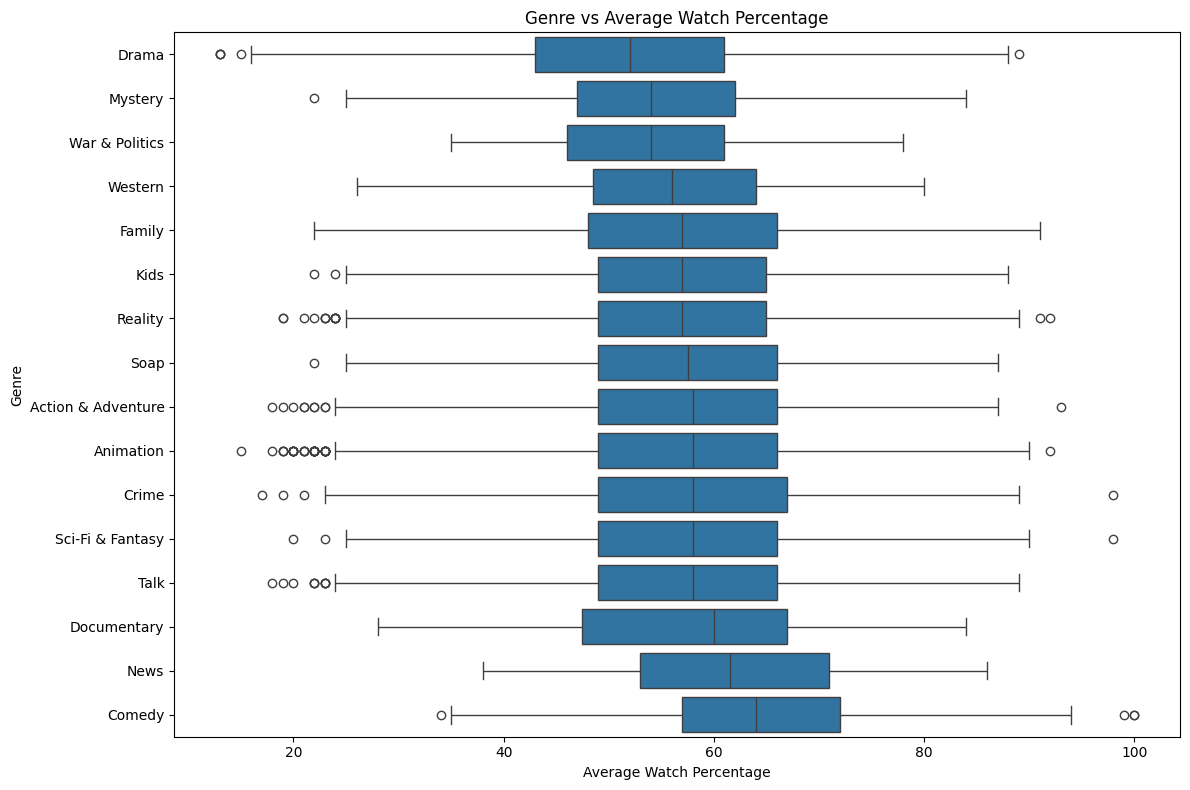

In [101]:
plt.figure(figsize=(12, 8))

genre_order = (
    df.groupby('genre')['avg_watch_percentage']
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df,
    x='avg_watch_percentage',
    y='genre',
    order=genre_order
)

plt.title('Genre vs Average Watch Percentage')
plt.xlabel('Average Watch Percentage')
plt.ylabel('Genre')

plt.tight_layout()
plt.show()

In [102]:
genre_watch = (
    df.groupby('genre')['avg_watch_percentage']
    .agg(['mean', 'median', 'count'])
    .sort_values('median')
)

print(genre_watch)

                         mean  median  count
genre                                       
Drama               52.108922    52.0   6142
Mystery             54.115880    54.0    233
War & Politics      54.568627    54.0     51
Western             55.802817    56.0     71
Family              56.706731    57.0    208
Kids                56.645570    57.0    632
Reality             56.881898    57.0   4005
Soap                57.230539    57.5    334
Action & Adventure  57.106695    58.0   4705
Animation           57.114280    58.0  10028
Crime               57.224622    58.0    926
Sci-Fi & Fantasy    57.425087    58.0    574
Talk                57.227580    58.0   2074
Documentary         57.253333    60.0     75
News                61.826087    61.5     46
Comedy              64.286273    64.0   3067


10. platform vs drop_off_probability
There are 28 platforms, so a horizontal boxplot is much easier to read.

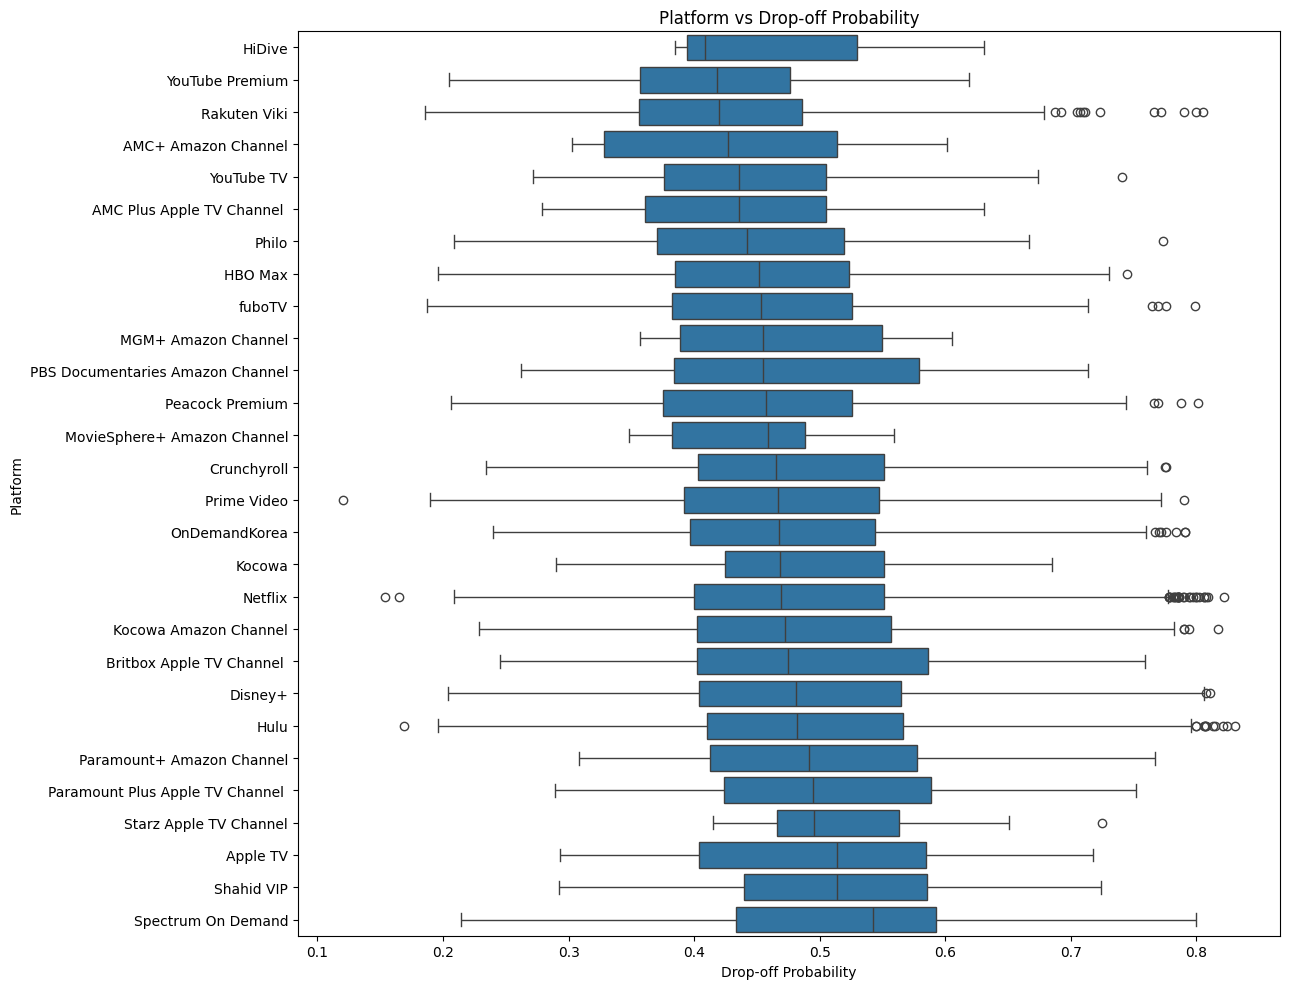

In [103]:
plt.figure(figsize=(13, 10))

platform_order = (
    df.groupby('platform')['drop_off_probability']
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df,
    x='drop_off_probability',
    y='platform',
    order=platform_order
)

plt.title('Platform vs Drop-off Probability')
plt.xlabel('Drop-off Probability')
plt.ylabel('Platform')

plt.tight_layout()
plt.show()

In [104]:
platform_dropoff = (
    df.groupby('platform')['drop_off_probability']
    .agg(['mean', 'median', 'count'])
    .sort_values('median')
)

print(platform_dropoff)

                                      mean  median  count
platform                                                 
HiDive                            0.467083  0.4085     12
YouTube Premium                   0.422659  0.4180    129
Rakuten Viki                      0.426380  0.4200    911
AMC+ Amazon Channel               0.433000  0.4270     10
YouTube TV                        0.449278  0.4355     54
AMC Plus Apple TV Channel         0.440560  0.4360     25
Philo                             0.450655  0.4420     55
HBO Max                           0.456248  0.4520    319
fuboTV                            0.457187  0.4530    550
MGM+ Amazon Channel               0.467600  0.4545     10
PBS Documentaries Amazon Channel  0.478778  0.4550     27
Peacock Premium                   0.458948  0.4570    686
MovieSphere+ Amazon Channel       0.443700  0.4585     10
Crunchyroll                       0.477442  0.4655    446
Prime Video                       0.473780  0.4670   2693
OnDemandKorea 

11. platform vs avg_watch_percentage.
Again, 28 platforms → horizontal boxplot.

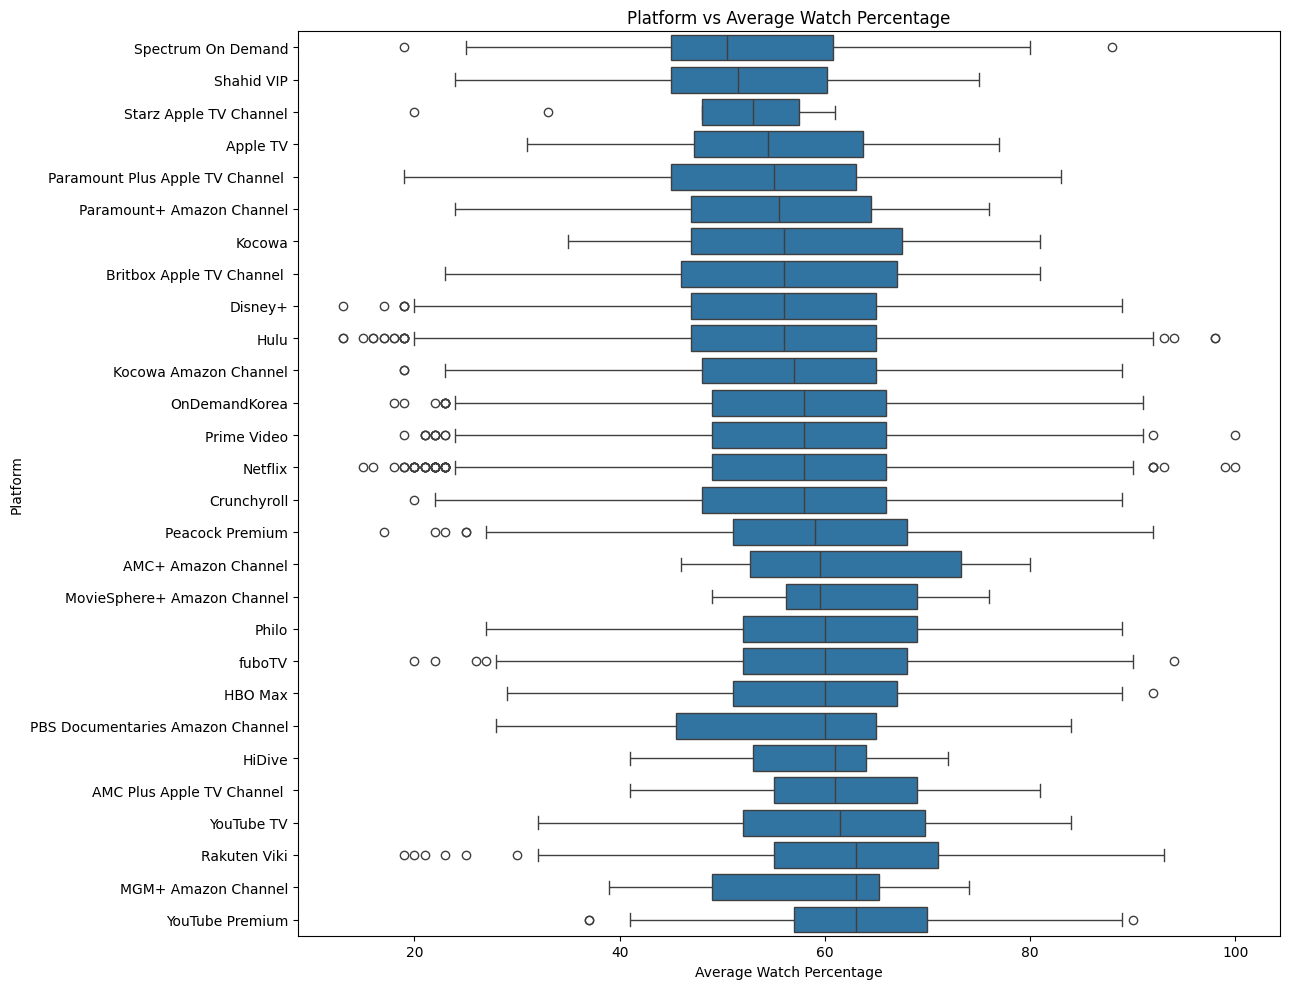

In [105]:
plt.figure(figsize=(13, 10))

platform_order = (
    df.groupby('platform')['avg_watch_percentage']
    .median()
    .sort_values()
    .index
)

sns.boxplot(
    data=df,
    x='avg_watch_percentage',
    y='platform',
    order=platform_order
)

plt.title('Platform vs Average Watch Percentage')
plt.xlabel('Average Watch Percentage')
plt.ylabel('Platform')

plt.tight_layout()
plt.show()

In [106]:
platform_watch = (
    df.groupby('platform')['avg_watch_percentage']
    .agg(['mean', 'median', 'count'])
    .sort_values('median')
)

print(platform_watch)

                                       mean  median  count
platform                                                  
Spectrum On Demand                52.208333    50.5     48
Shahid VIP                        51.600000    51.5     40
Starz Apple TV Channel            49.100000    53.0     10
Apple TV                          54.485714    54.5     70
Paramount Plus Apple TV Channel   53.906752    55.0    311
Paramount+ Amazon Channel         55.266667    55.5     30
Kocowa                            56.185185    56.0     27
Britbox Apple TV Channel          55.586826    56.0    167
Disney+                           55.888123    56.0   2467
Hulu                              55.441948    56.0   7967
Kocowa Amazon Channel             56.726503    57.0   2245
OnDemandKorea                     57.372314    58.0   1582
Prime Video                       57.237282    58.0   2693
Netflix                           56.955746    58.0  12270
Crunchyroll                       57.118834    58.0    4

12. skip_intro vs drop_off_probability.This is binary categorical × numerical, so a boxplot is appropriate.

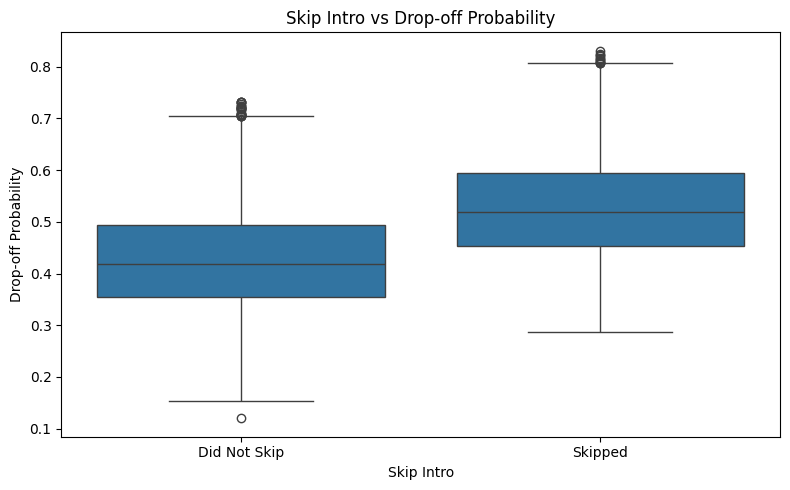

In [107]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='skip_intro',
    y='drop_off_probability',
    order=[0, 1]
)

plt.title('Skip Intro vs Drop-off Probability')
plt.xlabel('Skip Intro')
plt.ylabel('Drop-off Probability')

plt.xticks(
    [0, 1],
    ['Did Not Skip', 'Skipped']
)

plt.tight_layout()
plt.show()

In [108]:
skip_dropoff = (
    df.groupby('skip_intro')['drop_off_probability']
    .agg(['mean', 'median', 'count'])
)

print(skip_dropoff)

                mean  median  count
skip_intro                         
0           0.429007   0.418  16809
1           0.529209   0.520  16362


13. skip_intro vs actual drop_off
This one is different.
Both variables are categorical/binary:
skip_intro → 0 / 1
drop_off   → 0 / 1
So instead of a boxplot, we'll use a percentage crosstab.

In [109]:
skip_dropoff_ct = pd.crosstab(
    df['skip_intro'],
    df['drop_off'],
    normalize='index'
) * 100

print(skip_dropoff_ct)

drop_off            0          1
skip_intro                      
0           94.104349   5.895651
1           76.696003  23.303997


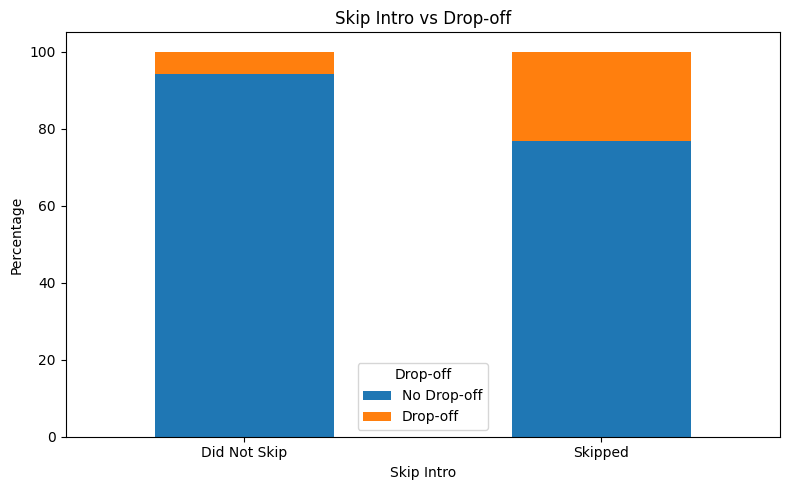

In [110]:
skip_dropoff_ct.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Skip Intro vs Drop-off')
plt.xlabel('Skip Intro')
plt.ylabel('Percentage')

plt.xticks(
    [0, 1],
    ['Did Not Skip', 'Skipped'],
    rotation=0
)

plt.legend(
    title='Drop-off',
    labels=['No Drop-off', 'Drop-off']
)

plt.tight_layout()
plt.show()

Engagement Analysis

In [111]:
# Step 1 — Engagement groups create karo
# Create engagement groups based on equal-sized quantiles

df['engagement_level'] = pd.qcut(
    df['avg_watch_percentage'],
    q=3,
    labels=['Low', 'Medium', 'High']
)

print(df['engagement_level'].value_counts())

engagement_level
Low       11875
Medium    10849
High      10447
Name: count, dtype: int64


In [112]:
# Step 2 — Actual boundaries dekho
print(
    df.groupby('engagement_level', observed=True)['avg_watch_percentage']
      .agg(['min', 'max', 'mean', 'median', 'count'])
)

                  min  max       mean  median  count
engagement_level                                    
Low                13   52  43.324800    45.0  11875
Medium             53   63  58.045903    58.0  10849
High               64  100  70.841581    70.0  10447


In [113]:
# Step 3 — Numerical variables ko ek saath analyse karo

engagement_numerical_cols = [
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'pause_count',
    'rewind_count',
    'cognitive_load',
    'drop_off_probability'
]

In [114]:
# Group statistics — ALL AT ONCE
for col in engagement_numerical_cols:

    print(f"\n{'='*60}")
    print(f"{col.upper()}")
    print('='*60)

    result = (
        df.groupby('engagement_level', observed=True)[col]
          .agg(['mean', 'median', 'count'])
    )

    print(result)



EPISODE_DURATION_MIN
                       mean  median  count
engagement_level                          
Low               37.892211    35.0  11875
Medium            37.499862    32.0  10849
High              37.564468    31.0  10447

PACING_SCORE
                      mean  median  count
engagement_level                         
Low               4.566821     4.0  11875
Medium            5.567426     6.0  10849
High              6.166555     6.0  10447

HOOK_STRENGTH
                      mean  median  count
engagement_level                         
Low               4.576337     4.0  11875
Medium            5.411835     5.0  10849
High              6.721355     7.0  10447

VISUAL_INTENSITY
                      mean  median  count
engagement_level                         
Low               6.036463     6.0  11875
Medium            5.991059     6.0  10849
High              5.997798     6.0  10447

PAUSE_COUNT
                      mean  median  count
engagement_level               

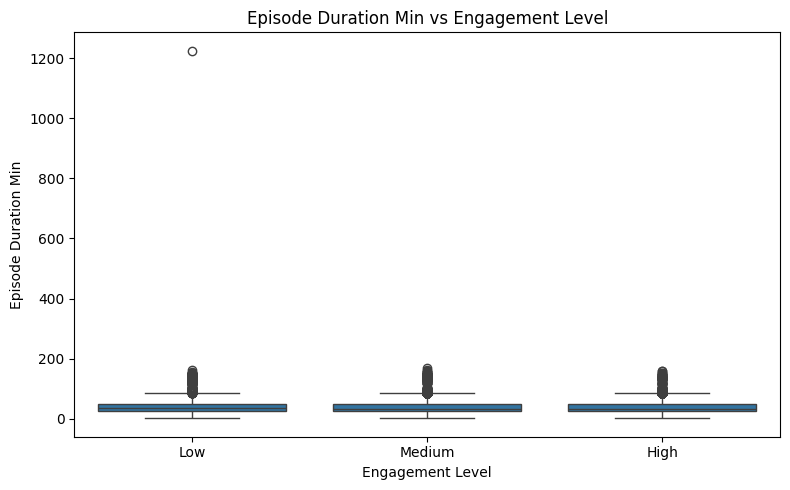

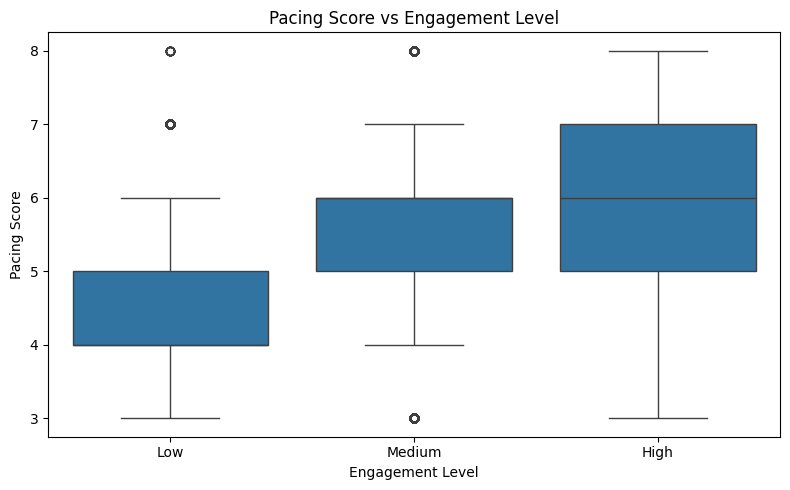

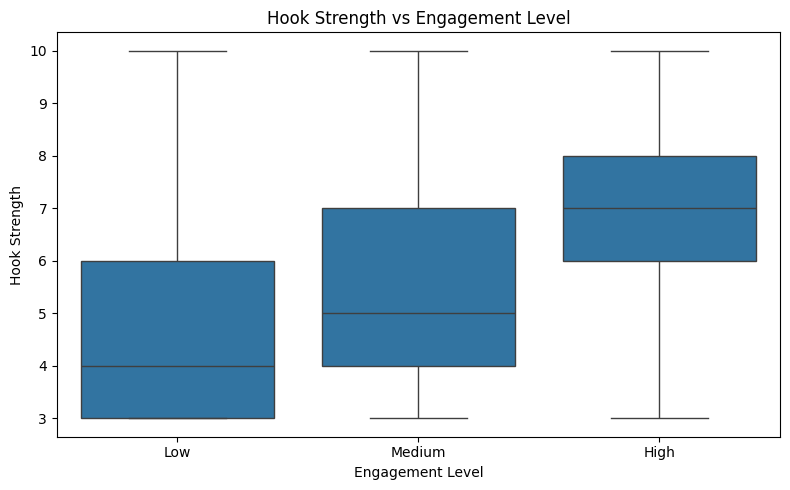

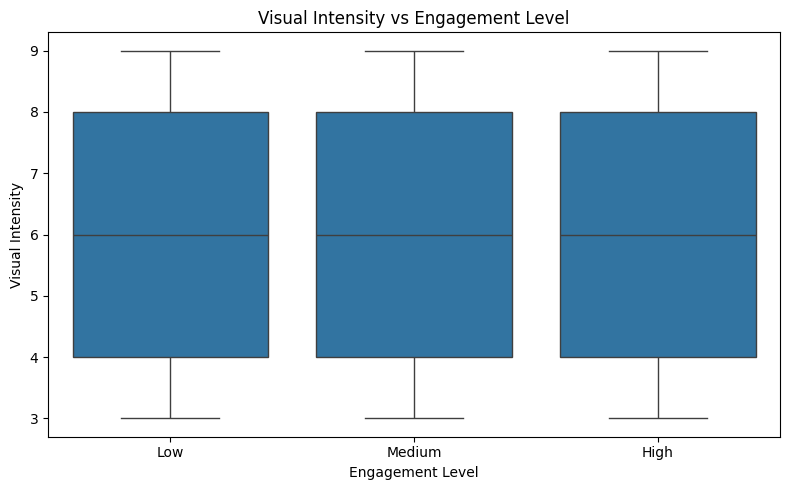

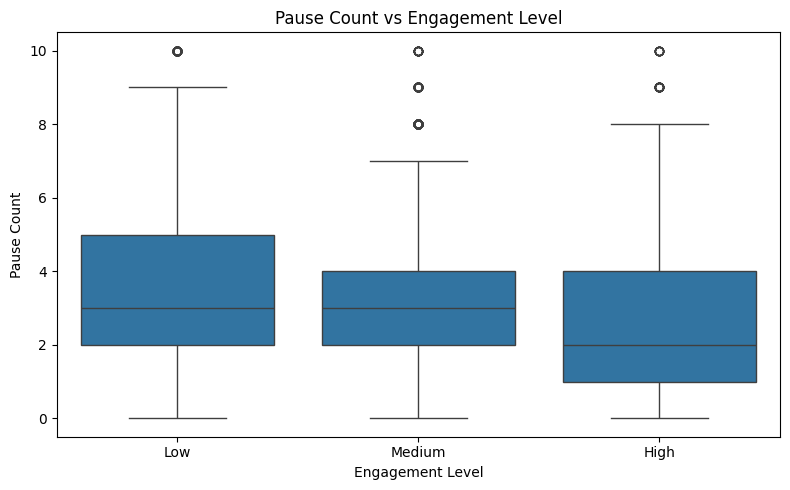

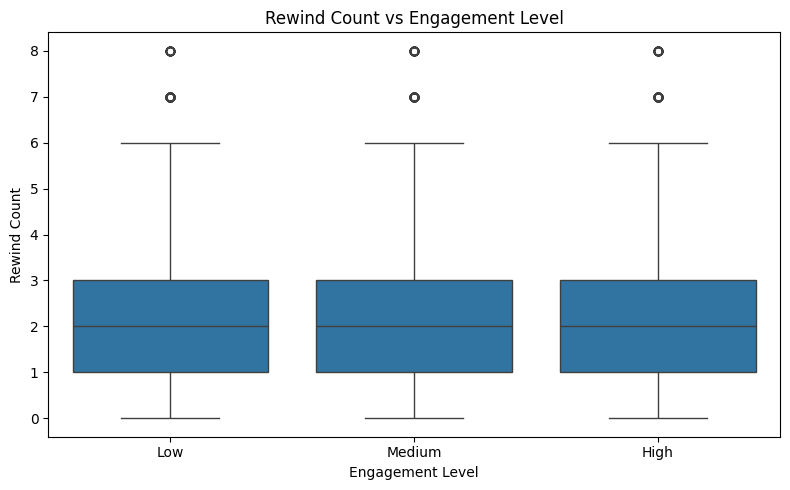

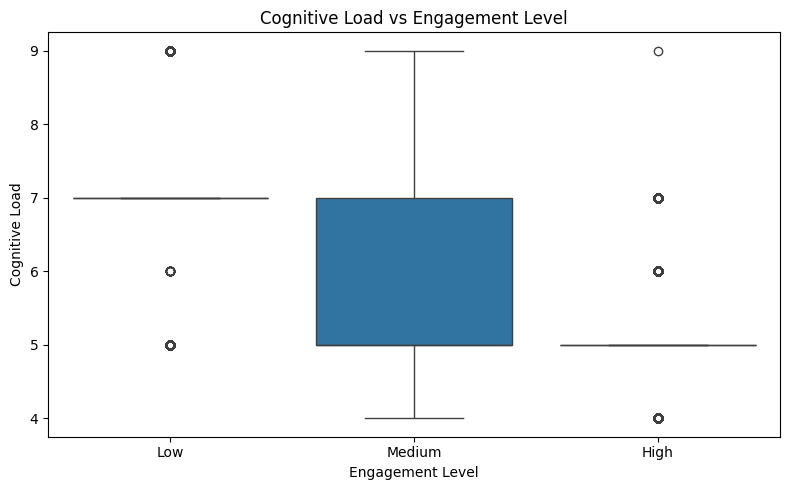

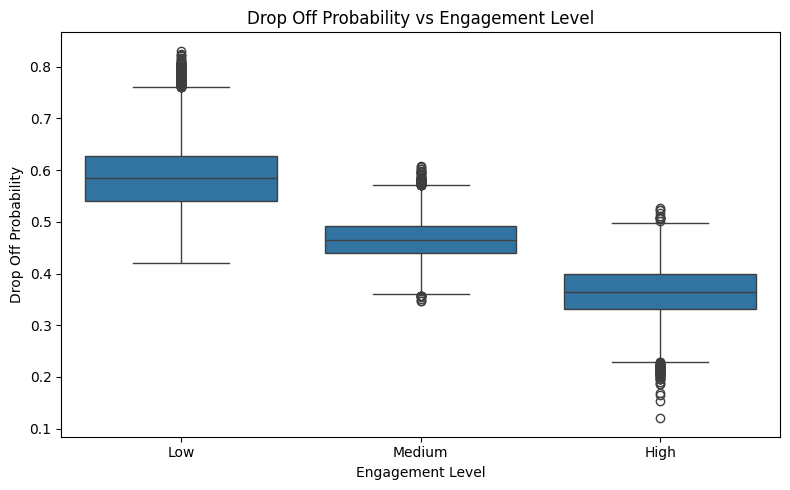

In [115]:
# ALL numerical boxplots ek saath
for col in engagement_numerical_cols:

    plt.figure(figsize=(8, 5))

    sns.boxplot(
        data=df,
        x='engagement_level',
        y=col,
        order=['Low', 'Medium', 'High']
    )

    plt.title(f'{col.replace("_", " ").title()} vs Engagement Level')
    plt.xlabel('Engagement Level')
    plt.ylabel(col.replace('_', ' ').title())

    plt.tight_layout()
    plt.show()


In [116]:
# Step 5 — Categorical variables ko ek saath analyse karo
engagement_categorical_cols = [
    'genre',
    'platform',
    'skip_intro',
    'dialogue_density',
    'attention_required',
    'retention_risk',
    'night_watch_safe'
]

In [117]:
for col in engagement_categorical_cols:

    print(f"\n{'='*60}")
    print(f"{col.upper()}")
    print('='*60)

    result = pd.crosstab(
        df['engagement_level'],
        df[col],
        normalize='index'
    ) * 100

    print(result.round(2))


GENRE
genre             Action & Adventure  Animation  Comedy  Crime  Documentary  \
engagement_level                                                              
Low                            13.66      29.07    3.74   2.66         0.21   
Medium                         14.74      31.04    9.38   2.83         0.23   
High                           14.21      30.72   15.36   2.90         0.24   

genre             Drama  Family  Kids  Mystery  News  Reality  \
engagement_level                                                
Low               26.38    0.61  1.82     0.87  0.09    12.10   
Medium            16.08    0.65  2.08     0.74  0.12    12.30   
High              12.10    0.63  1.82     0.48  0.21    11.81   

genre             Sci-Fi & Fantasy  Soap  Talk  War & Politics  Western  
engagement_level                                                         
Low                           1.55  0.99  5.85            0.19     0.21  
Medium                        1.86  1.00  6.54   

In [118]:
# Step 6 — Actual drop_off bhi compare karo
# Since drop_off is our actual binary outcome, isko separately check karna useful hai:
dropoff_by_engagement = pd.crosstab(
    df['engagement_level'],
    df['drop_off'],
    normalize='index'
) * 100

print(dropoff_by_engagement.round(2))

drop_off               0      1
engagement_level               
Low                59.58  40.42
Medium             99.96   0.04
High              100.00   0.00


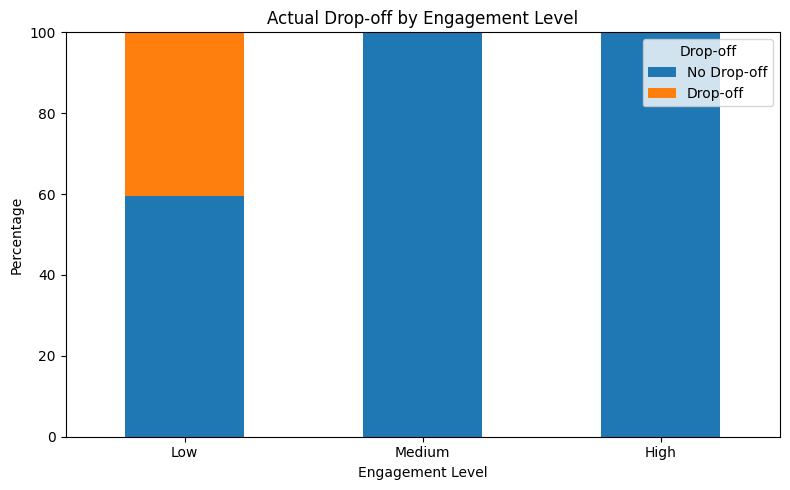

In [119]:
dropoff_by_engagement.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title('Actual Drop-off by Engagement Level')
plt.xlabel('Engagement Level')
plt.ylabel('Percentage')

plt.xticks(rotation=0)

plt.legend(
    title='Drop-off',
    labels=['No Drop-off', 'Drop-off']
)

plt.tight_layout()
plt.show()

In [120]:
# Step 7 — One important summary table
# Finally, let's create one compact table that compares the major variables across engagement levels.
summary_cols = [
    'avg_watch_percentage',
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'pause_count',
    'rewind_count',
    'cognitive_load',
    'drop_off_probability'
]

engagement_summary = (
    df.groupby('engagement_level', observed=True)[summary_cols]
      .mean()
      .T
)

print(engagement_summary.round(3))

engagement_level         Low  Medium    High
avg_watch_percentage  43.325  58.046  70.842
episode_duration_min  37.892  37.500  37.564
pacing_score           4.567   5.567   6.167
hook_strength          4.576   5.412   6.721
visual_intensity       6.036   5.991   5.998
pause_count            3.609   3.005   2.629
rewind_count           2.026   1.999   1.983
cognitive_load         7.251   5.947   5.255
drop_off_probability   0.590   0.466   0.364


Does retention risk change systematically with average watch percentage?

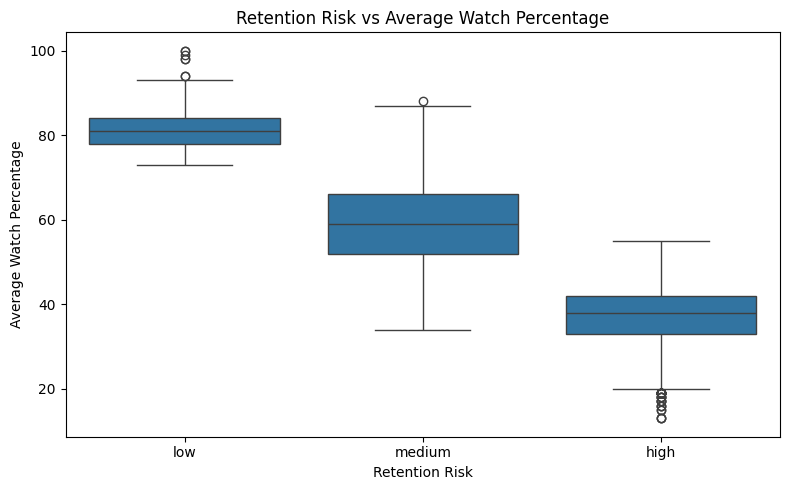

In [121]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='retention_risk',
    y='avg_watch_percentage',
    order=['low', 'medium', 'high']
)

plt.title('Retention Risk vs Average Watch Percentage')
plt.xlabel('Retention Risk')
plt.ylabel('Average Watch Percentage')

plt.tight_layout()
plt.show()

In [122]:
retention_watch = (
    df.groupby('retention_risk')['avg_watch_percentage']
      .agg(['mean', 'median', 'min', 'max', 'count'])
      .sort_values('median')
)

print(retention_watch)

                     mean  median  min  max  count
retention_risk                                    
high            37.082639    38.0   13   55   4804
medium          59.405335    59.0   34   88  27402
low             81.175130    81.0   73  100    965


In [123]:
retention_engagement = pd.crosstab(
    df['engagement_level'],
    df['retention_risk'],
    normalize='index'
) * 100

print(retention_engagement.round(2))

retention_risk     high   low  medium
engagement_level                     
Low               40.42  0.00   59.58
Medium             0.04  0.00   99.96
High               0.00  9.24   90.76


In [124]:
retention_dropoff = (
    df.groupby('retention_risk')['drop_off_probability']
      .agg(['mean', 'median', 'min', 'max', 'count'])
      .sort_values('median')
)

print(retention_dropoff)

                    mean  median   min    max  count
retention_risk                                      
low             0.275348   0.283  0.12  0.299    965
medium          0.454539   0.456  0.30  0.599  27402
high            0.655519   0.641  0.60  0.831   4804


Drop Off ANLYSIS

In [125]:
# Step 1 — Count + percentage of actual drop-off
dropoff_summary = pd.DataFrame({
    'Count': df['drop_off'].value_counts().sort_index(),
    'Percentage': df['drop_off'].value_counts(normalize=True).sort_index() * 100
})

dropoff_summary.index = ['No Drop-off', 'Drop-off']

print(dropoff_summary.round(2))

             Count  Percentage
No Drop-off  28367       85.52
Drop-off      4804       14.48


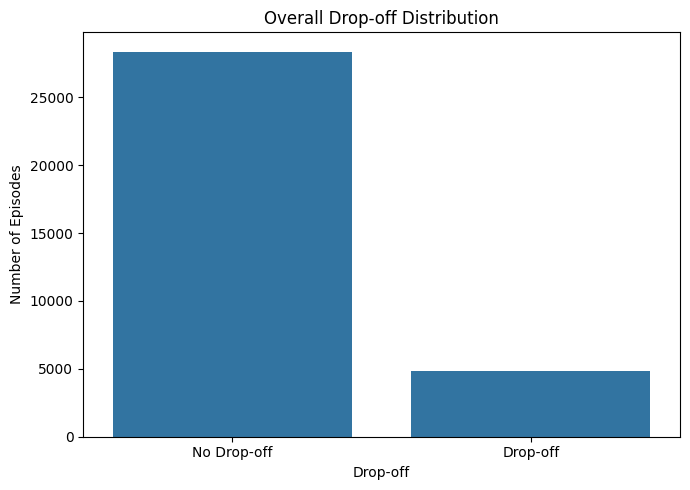

In [126]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x='drop_off'
)

plt.title('Overall Drop-off Distribution')
plt.xlabel('Drop-off')
plt.ylabel('Number of Episodes')

plt.xticks(
    [0, 1],
    ['No Drop-off', 'Drop-off']
)

plt.tight_layout()
plt.show()

In [127]:
# Step 3 — Check drop_off_probability
print(
    df['drop_off_probability']
      .describe()
      .round(3)
)

count    33171.000
mean         0.478
std          0.107
min          0.120
25%          0.400
50%          0.471
75%          0.553
max          0.831
Name: drop_off_probability, dtype: float64


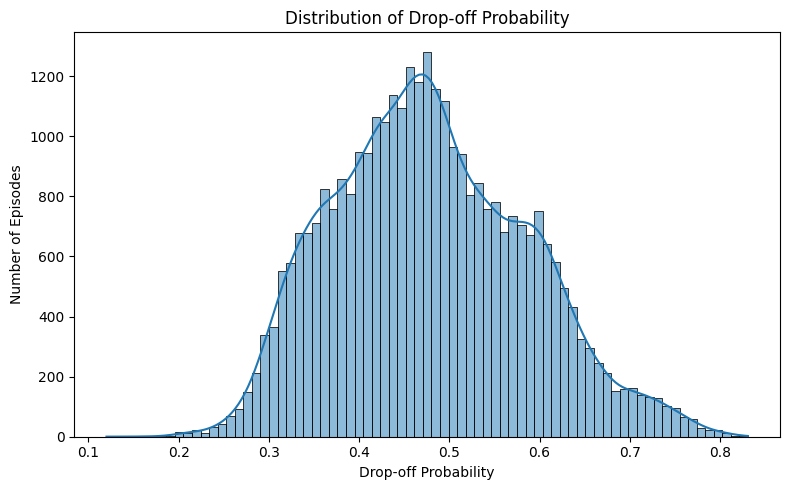

In [128]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x='drop_off_probability',
    kde=True
)

plt.title('Distribution of Drop-off Probability')
plt.xlabel('Drop-off Probability')
plt.ylabel('Number of Episodes')

plt.tight_layout()
plt.show()

In [129]:
dropoff_categorical_cols = [
    'genre',
    'platform',
    'skip_intro',
    'dialogue_density',
    'attention_required',
    'night_watch_safe'
]

for col in dropoff_categorical_cols:

    result = (
        df.groupby(col)['drop_off']
          .agg(['mean', 'count'])
          .rename(columns={'mean': 'drop_off_rate'})
    )

    result['drop_off_rate'] = result['drop_off_rate'] * 100

    result = result.sort_values('drop_off_rate', ascending=False)

    print(f"\n{'='*70}")
    print(f"{col.upper()} — DROP-OFF RATE")
    print('='*70)
    print(result.round(2))


GENRE — DROP-OFF RATE
                    drop_off_rate  count
genre                                   
Drama                       24.19   6142
Mystery                     18.88    233
Western                     18.31     71
Documentary                 17.33     75
Crime                       15.87    926
War & Politics              15.69     51
Reality                     13.56   4005
Animation                   13.48  10028
Soap                        13.17    334
Talk                        13.16   2074
Sci-Fi & Fantasy            13.07    574
Action & Adventure          13.05   4705
Family                      12.98    208
Kids                        11.87    632
News                         4.35     46
Comedy                       2.87   3067

PLATFORM — DROP-OFF RATE
                                  drop_off_rate  count
platform                                              
Kocowa                                    22.22     27
Britbox Apple TV Channel                  21.56 

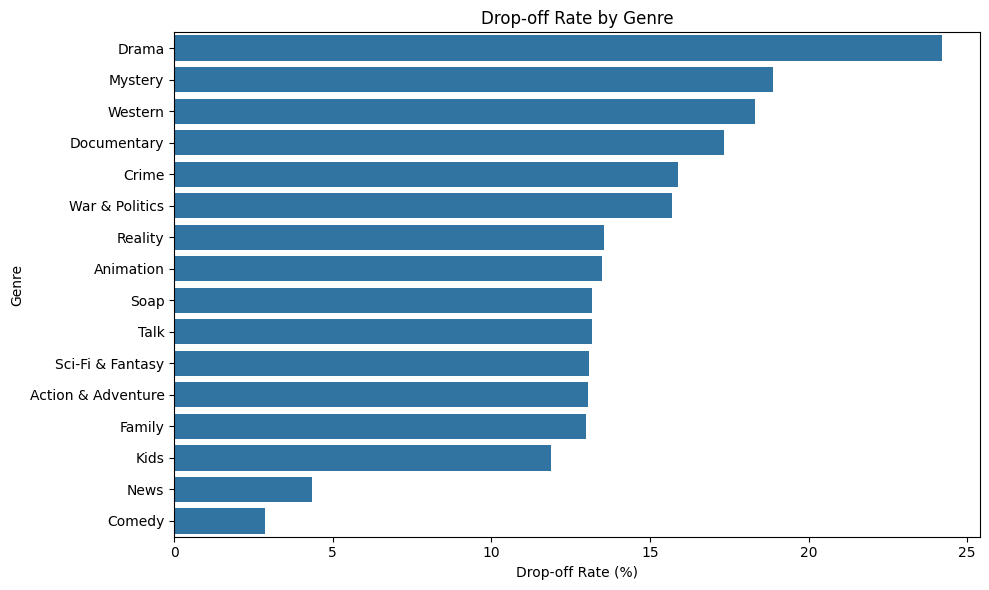

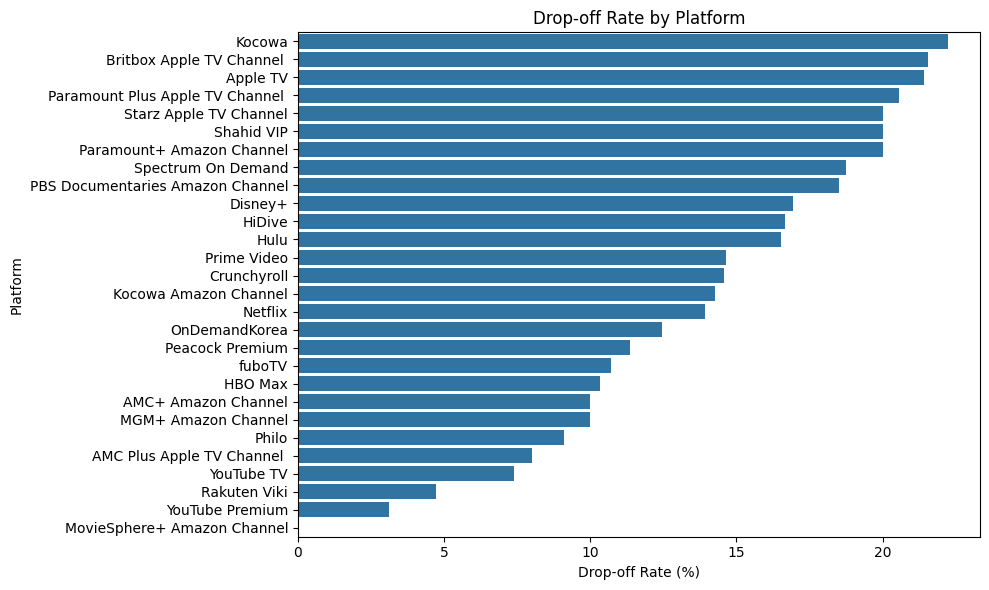

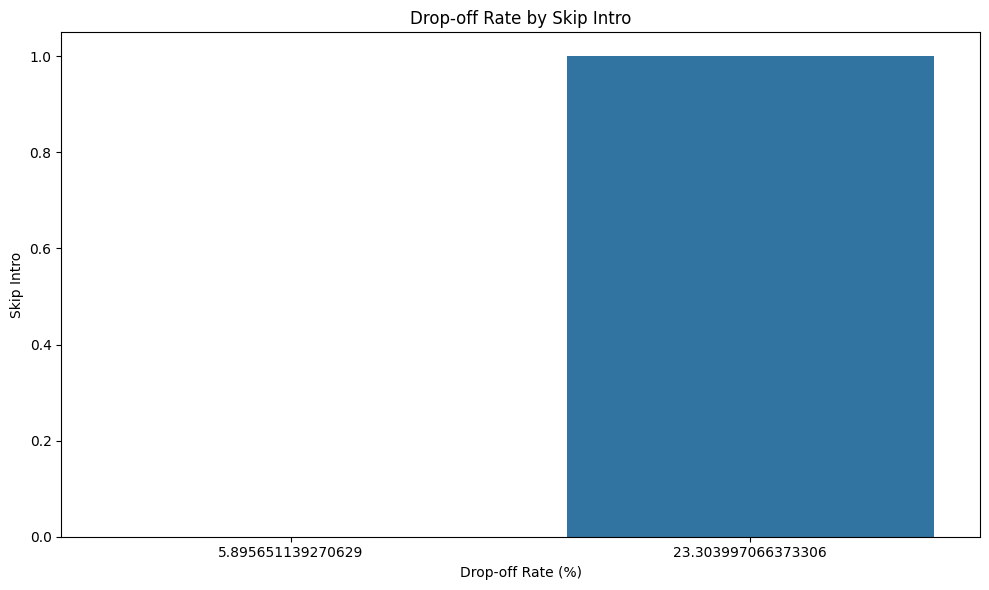

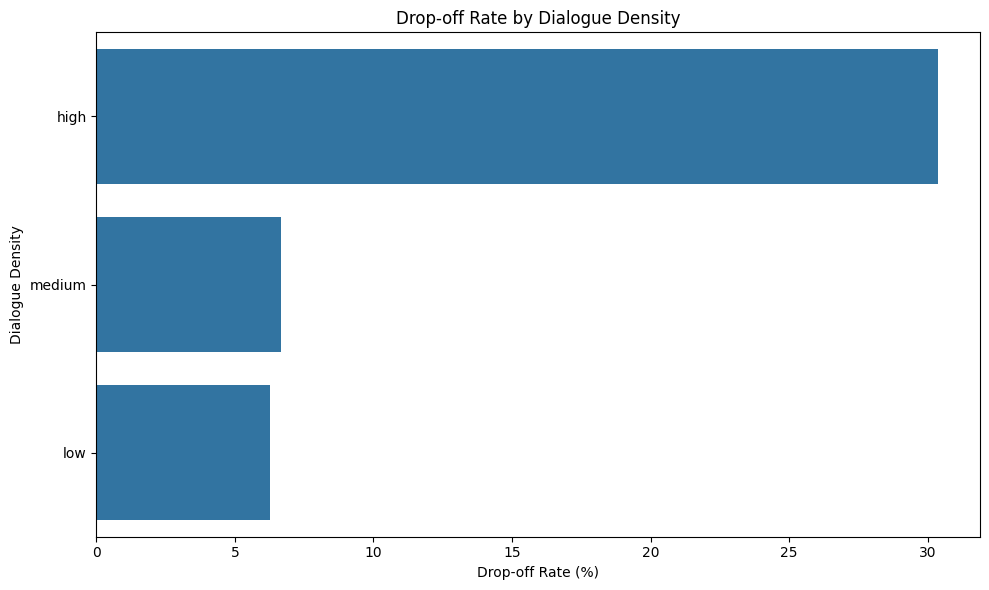

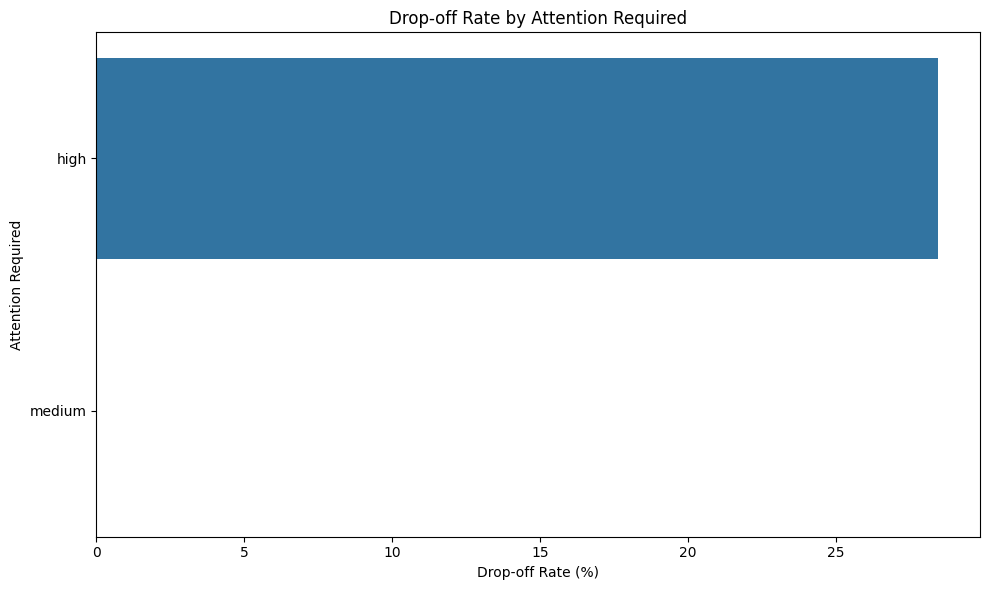

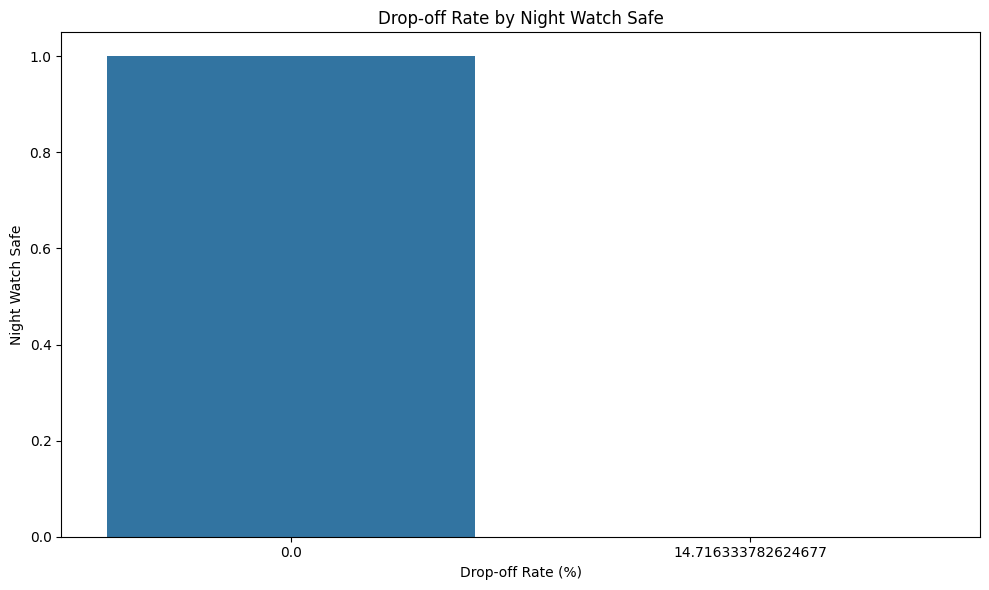

In [130]:
for col in dropoff_categorical_cols:

    dropoff_rate = (
        df.groupby(col)['drop_off']
          .mean()
          .mul(100)
          .sort_values(ascending=False)
    )

    plt.figure(figsize=(10, 6))

    sns.barplot(
        x=dropoff_rate.values,
        y=dropoff_rate.index
    )

    plt.title(f'Drop-off Rate by {col.replace("_", " ").title()}')
    plt.xlabel('Drop-off Rate (%)')
    plt.ylabel(col.replace('_', ' ').title())

    plt.tight_layout()
    plt.show()

In [131]:
for col in ['attention_required', 'night_watch_safe', 'dialogue_density']:
    print(f"\n{col}")
    print(pd.crosstab(df[col], df['drop_off'], margins=True))


attention_required
drop_off                0     1    All
attention_required                    
high                12074  4804  16878
medium              16293     0  16293
All                 28367  4804  33171

night_watch_safe
drop_off              0     1    All
night_watch_safe                    
0                 27840  4804  32644
1                   527     0    527
All               28367  4804  33171

dialogue_density
drop_off              0     1    All
dialogue_density                    
high               7740  3375  11115
low               10417   698  11115
medium            10210   731  10941
All               28367  4804  33171


avg_watch_percentage               episode_duration_min         \
                            mean median  count                 mean median   
No Drop-off               60.146   60.0  28367               37.661   32.0   
Drop-off                  37.083   38.0   4804               37.659   37.0   

                   pacing_score               hook_strength  ...  \
             count         mean median  count          mean  ...   
No Drop-off  28367        5.608    6.0  28367         5.742  ...   
Drop-off      4804        4.160    4.0   4804         4.245  ...   

            visual_intensity pause_count               rewind_count         \
                       count        mean median  count         mean median   
No Drop-off            28367       2.864    3.0  28367        2.002    2.0   
Drop-off                4804       4.516    4.0   4804        2.014    2.0   

                   cognitive_load                
             count           mean median  count  
No Drop-off  28367          5.886    5.0  28367  
Drop-off      4804          8.026    9.0   4804  

[2 rows x 24 columns]

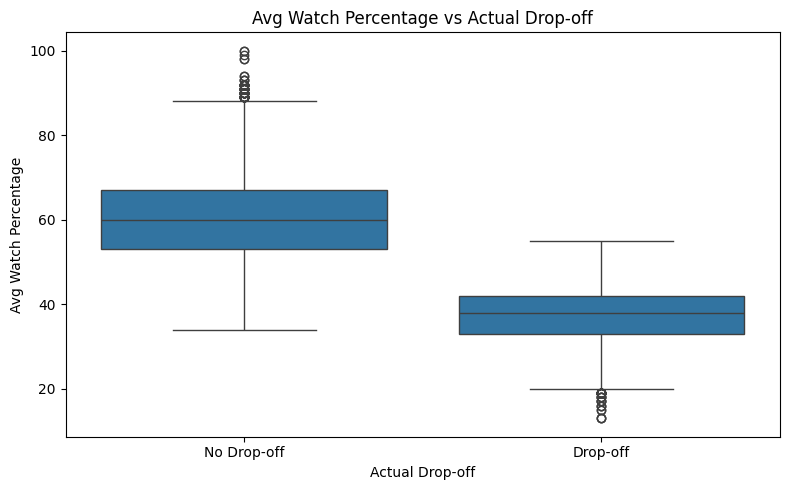

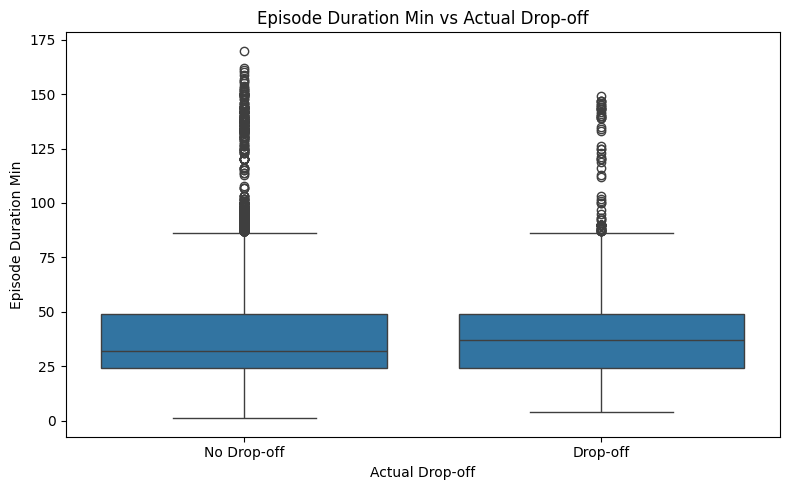

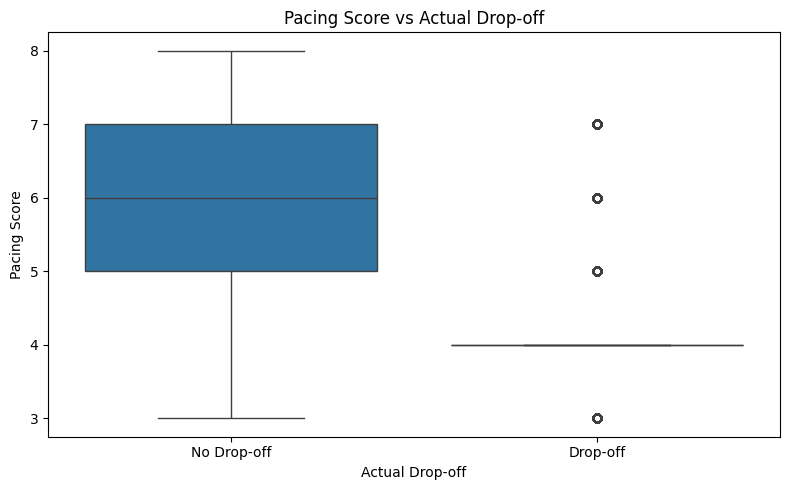

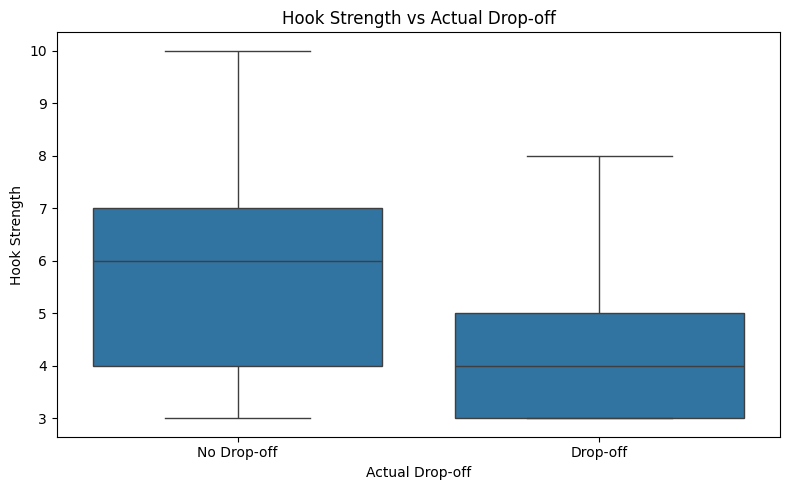

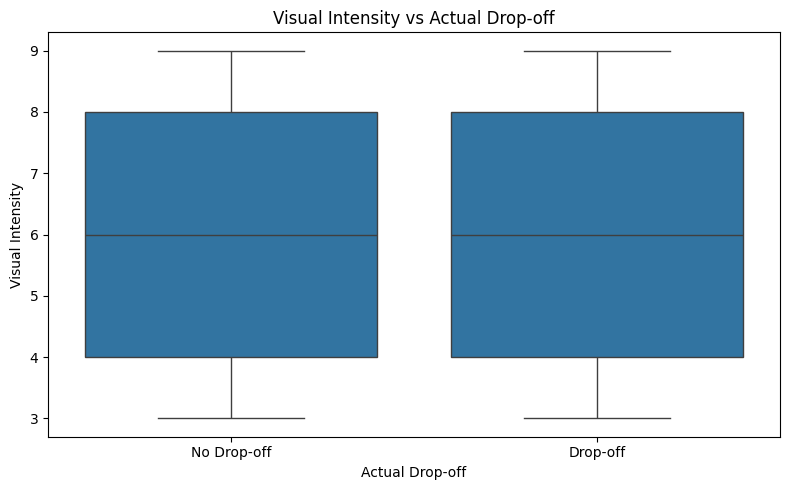

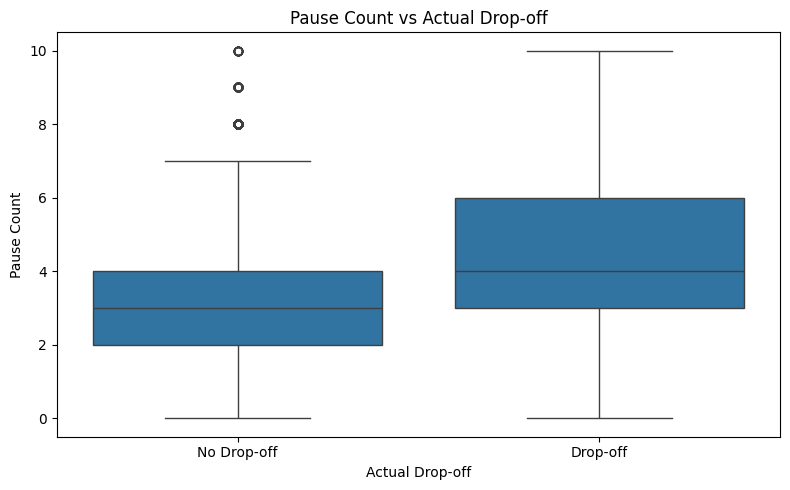

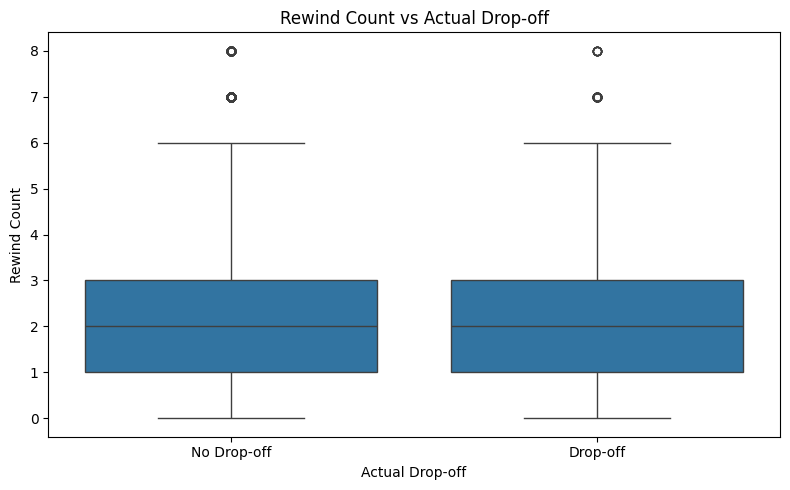

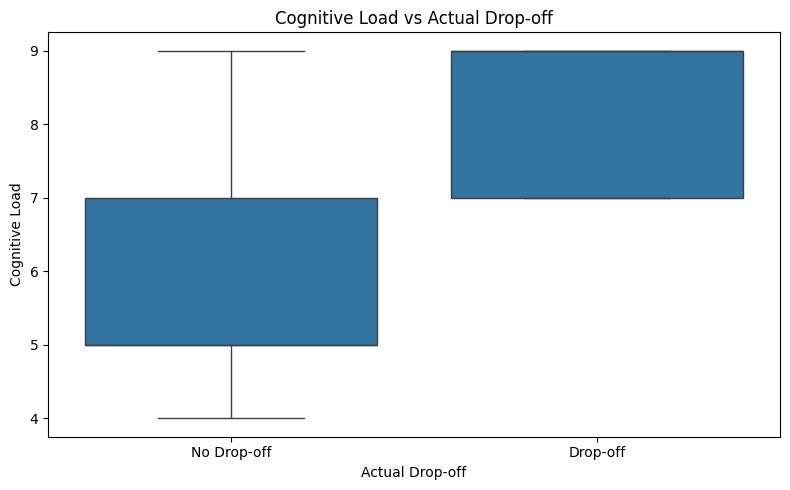

In [132]:
numerical_cols = [
    'avg_watch_percentage',
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'pause_count',
    'rewind_count',
    'cognitive_load'
]

# Summary statistics by actual drop-off outcome
summary = (
    df.groupby('drop_off')[numerical_cols]
      .agg(['mean', 'median', 'count'])
      .round(3)
)

summary.index = ['No Drop-off', 'Drop-off']
display(summary)

# Boxplots for all numerical variables
plot_df = df.copy()
plot_df['drop_off_label'] = plot_df['drop_off'].map({
    0: 'No Drop-off',
    1: 'Drop-off'
})

for col in numerical_cols:
    # Exclude the extreme duration anomaly from this plot only
    # so that the remaining duration distribution is easier to inspect.
    temp = plot_df
    if col == 'episode_duration_min':
        temp = plot_df[plot_df[col] <= 300]

    plt.figure(figsize=(8, 5))
    sns.boxplot(
        data=temp,
        x='drop_off_label',
        y=col,
        order=['No Drop-off', 'Drop-off']
    )
    plt.title(f'{col.replace("_", " ").title()} vs Actual Drop-off')
    plt.xlabel('Actual Drop-off')
    plt.ylabel(col.replace('_', ' ').title())
    plt.tight_layout()
    plt.show()

In [133]:
# 1. Check actual drop-off against its probability
print("DROP-OFF vs DROP-OFF PROBABILITY")
print(
    df.groupby('drop_off')['drop_off_probability']
      .agg(['count', 'mean', 'median', 'min', 'max'])
      .round(3)
)

# 2. Check whether retention risk aligns with actual drop-off
print("\nRETENTION RISK vs ACTUAL DROP-OFF")
print(pd.crosstab(
    df['retention_risk'],
    df['drop_off'],
    margins=True
))

# 3. Check suspicious categorical relationships
for col in ['attention_required', 'night_watch_safe', 'dialogue_density']:
    print(f"\n{col.upper()} vs DROP-OFF")
    print(pd.crosstab(
        df[col],
        df['drop_off'],
        margins=True
    ))

# 4. Check whether the binary outcome matches a probability threshold
print("\nDROP-OFF RATE BY PROBABILITY RANGE")

df['probability_band'] = pd.cut(
    df['drop_off_probability'],
    bins=[0, 0.3, 0.4, 0.5, 0.6, 0.7, 1.0],
    include_lowest=True
)

print(
    df.groupby('probability_band', observed=False)['drop_off']
      .agg(['mean', 'count'])
      .assign(drop_off_rate=lambda x: x['mean'] * 100)
      .drop(columns='mean')
      .round(2)
)

# Remove the temporary analysis column
df.drop(columns='probability_band', inplace=True)

DROP-OFF vs DROP-OFF PROBABILITY
          count   mean  median   min    max
drop_off                                   
0         28367  0.448   0.453  0.12  0.599
1          4804  0.656   0.641  0.60  0.831

RETENTION RISK vs ACTUAL DROP-OFF
drop_off            0     1    All
retention_risk                    
high                0  4804   4804
low               965     0    965
medium          27402     0  27402
All             28367  4804  33171

ATTENTION_REQUIRED vs DROP-OFF
drop_off                0     1    All
attention_required                    
high                12074  4804  16878
medium              16293     0  16293
All                 28367  4804  33171

NIGHT_WATCH_SAFE vs DROP-OFF
drop_off              0     1    All
night_watch_safe                    
0                 27840  4804  32644
1                   527     0    527
All               28367  4804  33171

DIALOGUE_DENSITY vs DROP-OFF
drop_off              0     1    All
dialogue_density                    


In [134]:
# Check whether actual drop-off matches a probability threshold
for threshold in [0.50, 0.55, 0.59, 0.60, 0.61]:
    predicted_dropoff = (
        df['drop_off_probability'] >= threshold
    ).astype(int)

    mismatches = (predicted_dropoff != df['drop_off']).sum()

    print(
        f"Threshold: {threshold:.2f} | "
        f"Mismatches: {mismatches}"
    )

# Inspect records around the apparent boundary
print("\nRecords around probability 0.60:")
print(
    df.loc[
        df['drop_off_probability'].between(0.58, 0.62),
        ['drop_off_probability', 'drop_off', 'retention_risk']
    ].sort_values('drop_off_probability').head(30)
)

Threshold: 0.50 | Mismatches: 8341
Threshold: 0.55 | Mismatches: 3788
Threshold: 0.59 | Mismatches: 740
Threshold: 0.60 | Mismatches: 0
Threshold: 0.61 | Mismatches: 713

Records around probability 0.60:
       drop_off_probability  drop_off retention_risk
2734                   0.58         0         medium
21696                  0.58         0         medium
16649                  0.58         0         medium
29643                  0.58         0         medium
15325                  0.58         0         medium
13646                  0.58         0         medium
6617                   0.58         0         medium
20825                  0.58         0         medium
24615                  0.58         0         medium
11413                  0.58         0         medium
6667                   0.58         0         medium
30227                  0.58         0         medium
23388                  0.58         0         medium
24461                  0.58         0         medium
2

In [135]:
# 1. Exact values around the threshold
print("Values around 0.60:")
print(
    df.loc[
        df['drop_off_probability'].between(0.59, 0.61),
        ['drop_off_probability', 'drop_off', 'retention_risk']
    ]
    .sort_values('drop_off_probability')
    .drop_duplicates()
    .to_string(index=False)
)

# 2. Check whether drop_off is perfectly determined by probability
print("\nDrop-off counts by probability threshold:")
print(
    pd.crosstab(
        df['drop_off_probability'] >= 0.60,
        df['drop_off'],
        rownames=['Probability >= 0.60'],
        colnames=['Actual Drop-off']
    )
)

# 3. Check the exact probability values for each actual outcome
print("\nProbability range by actual drop-off:")
print(
    df.groupby('drop_off')['drop_off_probability']
      .agg(['min', 'max', 'mean', 'median', 'count'])
      .round(3)
)

Values around 0.60:
 drop_off_probability  drop_off retention_risk
                0.590         0         medium
                0.591         0         medium
                0.592         0         medium
                0.593         0         medium
                0.594         0         medium
                0.595         0         medium
                0.596         0         medium
                0.597         0         medium
                0.598         0         medium
                0.599         0         medium
                0.600         1           high
                0.601         1           high
                0.602         1           high
                0.603         1           high
                0.604         1           high
                0.605         1           high
                0.606         1           high
                0.607         1           high
                0.608         1           high
                0.609         1         

In [136]:
# Step 1: Identify the target and suspicious features

target = 'drop_off'

suspicious_cols = [
    'drop_off_probability',
    'retention_risk',
    'avg_watch_percentage',
    'attention_required',
    'night_watch_safe'
]

print("TARGET COLUMN:", target)
print("TARGET DISTRIBUTION:")
print(df[target].value_counts())
print("\nTARGET PERCENTAGES:")
print((df[target].value_counts(normalize=True) * 100).round(2))

print("\nSUSPICIOUS FEATURES:")
for col in suspicious_cols:
    print(f"{col}: {df[col].nunique()} unique values")

TARGET COLUMN: drop_off
TARGET DISTRIBUTION:
drop_off
0    28367
1     4804
Name: count, dtype: int64

TARGET PERCENTAGES:
drop_off
0    85.52
1    14.48
Name: proportion, dtype: float64

SUSPICIOUS FEATURES:
drop_off_probability: 610 unique values
retention_risk: 3 unique values
avg_watch_percentage: 84 unique values
attention_required: 2 unique values
night_watch_safe: 2 unique values


In [137]:
# Step 2: Check categorical features against the target

for col in [
    'retention_risk',
    'attention_required',
    'night_watch_safe'
]:
    print(f"\n--- {col} vs {target} ---")

    print(pd.crosstab(
        df[col],
        df[target],
        margins=True
    ))

    print("\nDrop-off rate (%):")
    print(
        df.groupby(col, observed=True)[target]
          .mean()
          .mul(100)
          .round(2)
    )


--- retention_risk vs drop_off ---
drop_off            0     1    All
retention_risk                    
high                0  4804   4804
low               965     0    965
medium          27402     0  27402
All             28367  4804  33171

Drop-off rate (%):
retention_risk
high      100.0
low         0.0
medium      0.0
Name: drop_off, dtype: float64

--- attention_required vs drop_off ---
drop_off                0     1    All
attention_required                    
high                12074  4804  16878
medium              16293     0  16293
All                 28367  4804  33171

Drop-off rate (%):
attention_required
high      28.46
medium     0.00
Name: drop_off, dtype: float64

--- night_watch_safe vs drop_off ---
drop_off              0     1    All
night_watch_safe                    
0                 27840  4804  32644
1                   527     0    527
All               28367  4804  33171

Drop-off rate (%):
night_watch_safe
0    14.72
1     0.00
Name: drop_off, dtype

In [138]:
# Step 3: Verify the threshold rule

predicted_drop_off = (
    df['drop_off_probability'] >= 0.60
).astype(int)

mismatches = (
    predicted_drop_off != df['drop_off']
).sum()

print("Total records:", len(df))
print("Mismatches:", mismatches)
print(
    "Exact match:",
    predicted_drop_off.equals(df['drop_off'])
)

Total records: 33171
Mismatches: 0
Exact match: False


In [139]:
print("Original target dtype:", df['drop_off'].dtype)
print("Predicted target dtype:", predicted_drop_off.dtype)

print("Same index:", predicted_drop_off.index.equals(df['drop_off'].index))
print("Same values:", (predicted_drop_off == df['drop_off']).all())
print("Mismatches:", (predicted_drop_off != df['drop_off']).sum())

Original target dtype: int64
Predicted target dtype: int32
Same index: True
Same values: True
Mismatches: 0


In [140]:
print(
    df.groupby('drop_off')['avg_watch_percentage']
      .agg(['count', 'mean', 'median', 'min', 'max'])
      .round(2)
)

print("\nWatch percentage by retention risk:")
print(
    df.groupby('retention_risk', observed=True)['avg_watch_percentage']
      .agg(['count', 'mean', 'median', 'min', 'max'])
      .round(2)
)

          count   mean  median  min  max
drop_off                                
0         28367  60.15    60.0   34  100
1          4804  37.08    38.0   13   55

Watch percentage by retention risk:
                count   mean  median  min  max
retention_risk                                
high             4804  37.08    38.0   13   55
low               965  81.18    81.0   73  100
medium          27402  59.41    59.0   34   88


# 10. Retention Analysis


In [141]:
# 10. Retention Analysis

print("OVERALL WATCH PERCENTAGE")
print(
    df['avg_watch_percentage']
      .describe()
      .round(2)
)

print("\nWATCH PERCENTAGE BY GENRE")
print(
    df.groupby('genre', observed=True)['avg_watch_percentage']
      .agg(['count', 'mean', 'median'])
      .sort_values('median', ascending=False)
      .round(2)
)

print("\nWATCH PERCENTAGE BY PLATFORM")
print(
    df.groupby('platform', observed=True)['avg_watch_percentage']
      .agg(['count', 'mean', 'median'])
      .sort_values('median', ascending=False)
      .round(2)
)

OVERALL WATCH PERCENTAGE
count    33171.00
mean        56.81
std         12.58
min         13.00
25%         48.00
50%         57.00
75%         66.00
max        100.00
Name: avg_watch_percentage, dtype: float64

WATCH PERCENTAGE BY GENRE
                    count   mean  median
genre                                   
Comedy               3067  64.29    64.0
News                   46  61.83    61.5
Documentary            75  57.25    60.0
Action & Adventure   4705  57.11    58.0
Animation           10028  57.11    58.0
Crime                 926  57.22    58.0
Sci-Fi & Fantasy      574  57.43    58.0
Talk                 2074  57.23    58.0
Soap                  334  57.23    57.5
Family                208  56.71    57.0
Kids                  632  56.65    57.0
Reality              4005  56.88    57.0
Western                71  55.80    56.0
Mystery               233  54.12    54.0
War & Politics         51  54.57    54.0
Drama                6142  52.11    52.0

WATCH PERCENTAGE BY PL

In [142]:
# 11. Season & Episode Analysis

print("SEASON NUMBER DISTRIBUTION")
print(df['season_number'].value_counts().sort_index())

print("\nEPISODE NUMBER SUMMARY")
print(df['episode_number'].describe().round(2))

# Group episode numbers into ranges
df['episode_range'] = pd.cut(
    df['episode_number'],
    bins=[0, 10, 25, 50, 100, float('inf')],
    labels=['1-10', '11-25', '26-50', '51-100', '100+']
)

print("\nWATCH PERCENTAGE BY EPISODE RANGE")
print(
    df.groupby('episode_range', observed=True)
      .agg(
          episode_count=('episode_number', 'count'),
          median_watch=('avg_watch_percentage', 'median'),
          mean_watch=('avg_watch_percentage', 'mean'),
          drop_off_rate=('drop_off', 'mean')
      )
      .assign(drop_off_rate=lambda x: x['drop_off_rate'] * 100)
      .round(2)
)

SEASON NUMBER DISTRIBUTION
season_number
1    33171
Name: count, dtype: int64

EPISODE NUMBER SUMMARY
count    33171.00
mean       423.72
std        557.69
min          1.00
25%         27.00
50%        178.00
75%        611.00
max       2650.00
Name: episode_number, dtype: float64

WATCH PERCENTAGE BY EPISODE RANGE
               episode_count  median_watch  mean_watch  drop_off_rate
episode_range                                                        
1-10                    4613          58.0       57.21          14.83
11-25                   3562          58.0       56.79          15.61
26-50                   2197          57.0       56.89          12.52
51-100                  2888          57.0       57.04          14.23
100+                   19911          57.0       56.67          14.45


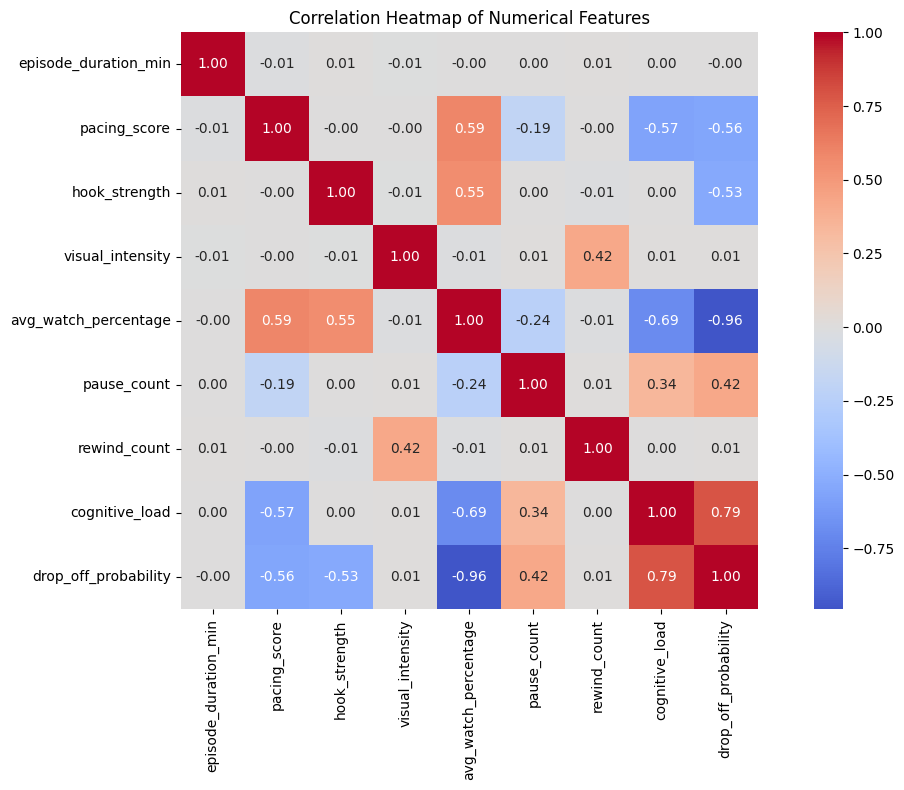

In [143]:
# 12. Correlation Analysis

import matplotlib.pyplot as plt
import seaborn as sns

corr_cols = [
    'episode_duration_min',
    'pacing_score',
    'hook_strength',
    'visual_intensity',
    'avg_watch_percentage',
    'pause_count',
    'rewind_count',
    'cognitive_load',
    'drop_off_probability'
]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    square=True
)

plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

In [144]:
print(df[['title', 'avg_watch_percentage', 'drop_off']].dtypes)

print("\nWatch percentage data type counts:")
print(df['avg_watch_percentage'].map(type).value_counts())

title                   object
avg_watch_percentage     int64
drop_off                 int64
dtype: object

Watch percentage data type counts:
avg_watch_percentage
<class 'int'>    33171
Name: count, dtype: int64


In [145]:
print(df['title'].map(type).value_counts())
print(df['drop_off'].map(type).value_counts())

title
<class 'str'>                  33137
<class 'int'>                     24
<class 'datetime.datetime'>       10
Name: count, dtype: int64
drop_off
<class 'int'>    33171
Name: count, dtype: int64


In [146]:
# Find non-string values in title

invalid_titles = df[
    ~df['title'].map(lambda x: isinstance(x, str))
]

print("Non-string title records:", len(invalid_titles))
print(invalid_titles[['title', 'platform', 'genre']].head(40))

Non-string title records: 34
                    title platform               genre
1158                   24     Hulu  Action & Adventure
1159                   24     Hulu  Action & Adventure
1160                   24     Hulu  Action & Adventure
1161                   24     Hulu  Action & Adventure
1162                   24     Hulu  Action & Adventure
1163                   24     Hulu  Action & Adventure
1164                   24     Hulu  Action & Adventure
1165                   24     Hulu  Action & Adventure
1166                   24     Hulu  Action & Adventure
1167                   24     Hulu  Action & Adventure
1168                   24     Hulu  Action & Adventure
1169                   24     Hulu  Action & Adventure
1170                   24     Hulu  Action & Adventure
1171                   24     Hulu  Action & Adventure
1172                   24     Hulu  Action & Adventure
1173                   24     Hulu  Action & Adventure
1174                   24     Hulu  

In [147]:
# 13. Top/Bottom Content

df_temp = df.copy()

# Create a temporary string grouping key
df_temp['title_key'] = df_temp['title'].map(str)

content_ranking = (
    df_temp.groupby('title_key', observed=True, sort=False)
      .agg(
          record_count=('avg_watch_percentage', 'count'),
          avg_watch=('avg_watch_percentage', 'mean'),
          median_watch=('avg_watch_percentage', 'median'),
          drop_off_rate=('drop_off', 'mean')
      )
)

# Keep titles with at least 10 records
content_ranking = content_ranking[
    content_ranking['record_count'] >= 10
].copy()

content_ranking['drop_off_rate'] *= 100

print("TOP 10 CONTENT BY MEDIAN WATCH")
print(
    content_ranking.sort_values(
        'median_watch', ascending=False
    ).head(10).round(2)
)

print("\nBOTTOM 10 CONTENT BY MEDIAN WATCH")
print(
    content_ranking.sort_values(
        'median_watch', ascending=True
    ).head(10).round(2)
)

TOP 10 CONTENT BY MEDIAN WATCH
                            record_count  avg_watch  median_watch  \
title_key                                                           
Californication                       12      71.92          73.0   
Curb Your Enthusiasm                  10      68.70          72.0   
Mom                                   22      66.68          70.0   
Young Sheldon                         22      69.05          69.5   
How I Met Your Mother                 22      66.55          69.0   
The Jewel of Section E                16      67.38          69.0   
Will & Grace                          22      68.32          68.0   
The Manipulated                       12      62.58          67.5   
Record of Ragnarok                    12      65.08          67.5   
A Wild Last Boss Appeared!            12      61.33          67.0   

                            drop_off_rate  
title_key                                  
Californication                      0.00  
Curb You